In [1]:
# ============================================================
# STEP 1 — IMPORTS AND FILE PATHS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gc

NEW_FILE = "Consultation.csv"
OLD_FILE = "consultations_freetext.csv"
CLINIC_FILE = "Clinics.csv"

pd.set_option("display.max_columns", None)

print("Setup complete.")

Setup complete.


In [2]:
# ============================================================
# STEP 2 — CLINIC ID / PSEUDONYM CONVERSION
# ============================================================

def pseudonym_to_id(series):
    """
    Convert values such as Clinic_08 -> 8.
    """
    return pd.to_numeric(
        series.astype(str).str.extract(r"(\d+)", expand=False),
        errors="coerce"
    )

print("Clinic conversion function created.")

Clinic conversion function created.


In [3]:
# ============================================================
# STEP 3 — CONSULTATION KEY OVERLAP
# ============================================================
# Both files contain ConsultationKey.
# We check whether the same consultations appear in both files
# so that we know whether duplicate removal is required.

new_keys = set(
    pd.read_csv(
        NEW_FILE,
        usecols=["ConsultationKey"]
    )["ConsultationKey"]
    .dropna()
    .astype(str)
    .unique()
)

print("NEW unique ConsultationKeys:", len(new_keys))

overlap_count = 0
old_unique_keys = set()

for chunk in pd.read_csv(
    OLD_FILE,
    usecols=["ConsultationKey"],
    chunksize=200_000
):
    
    keys = set(
        chunk["ConsultationKey"]
        .dropna()
        .astype(str)
    )

    old_unique_keys.update(keys)
    overlap_count += len(keys.intersection(new_keys))

print("OLD unique ConsultationKeys:", len(old_unique_keys))

actual_overlap = new_keys.intersection(old_unique_keys)

print("ConsultationKeys present in BOTH:", len(actual_overlap))

NEW unique ConsultationKeys: 1048575
OLD unique ConsultationKeys: 6139791
ConsultationKeys present in BOTH: 152256


In [4]:
# Free unnecessary memory
del old_unique_keys
gc.collect()

0

In [5]:
# ============================================================
# STEP 4 — PREPARE NEW CONSULTATION DATA
# ============================================================
# New Consultation.csv provides the historical
# consultation data covering approximately 2021–2023.
#
# We retain only:
#   ConsultationKey
#   ClinicID
#   ConsultationDate
#   ItemServiceFeeName
#
# Multiple rows can belong to the same consultation, so we
# collapse to one row per ConsultationKey.

new_consult = pd.read_csv(
    NEW_FILE,
    usecols=[
        "ConsultationKey",
        "ClinicID",
        "ConsultationDate",
        "ItemServiceFeeName"
    ],
    low_memory=False
)

# Correct Australian date format
new_consult["ConsultationDate"] = pd.to_datetime(
    new_consult["ConsultationDate"],
    errors="coerce",
    dayfirst=True
)

# Ensure numeric clinic IDs
new_consult["ClinicID"] = pd.to_numeric(
    new_consult["ClinicID"],
    errors="coerce"
)

print("Raw rows:", len(new_consult))
print("Unique consultations:",
      new_consult["ConsultationKey"].nunique())

print(
    "Date range:",
    new_consult["ConsultationDate"].min(),
    "to",
    new_consult["ConsultationDate"].max()
)

Raw rows: 1048575
Unique consultations: 1048575
Date range: 2021-10-01 00:00:00 to 2023-10-31 00:00:00


In [6]:
# ============================================================
# STEP 5 — COLLAPSE NEW DATA TO CONSULTATION LEVEL
# ============================================================
# One ConsultationKey may have several service-item rows.
# We collapse those rows into ONE consultation.
#
# ItemServiceFeeName values are joined together so that no
# service description is lost at this stage.

new_consult["ItemServiceFeeName"] = (
    new_consult["ItemServiceFeeName"]
    .fillna("")
    .astype(str)
)

new_consult_one = (
    new_consult
    .groupby("ConsultationKey", as_index=False)
    .agg(
        ClinicID=("ClinicID", "first"),
        ConsultationDate=("ConsultationDate", "min"),
        ItemServiceFeeName=(
            "ItemServiceFeeName",
            lambda x: " | ".join(
                pd.unique(x[x.ne("")])
            )
        )
    )
)

# Create pseudonym in the same format as the old dataset
new_consult_one["ClinicPseudonym"] = (
    "Clinic_"
    + new_consult_one["ClinicID"]
      .astype("Int64")
      .astype(str)
      .str.zfill(2)
)

new_consult_one["DataSource"] = "Consultation.csv"

print("NEW consultation-level rows:",
      len(new_consult_one))

print(
    "Period:",
    new_consult_one["ConsultationDate"].min(),
    "to",
    new_consult_one["ConsultationDate"].max()
)

display(new_consult_one.head())

NEW consultation-level rows: 1048575
Period: 2021-10-01 00:00:00 to 2023-10-31 00:00:00


,ConsultationKey,ClinicID,ConsultationDate,ItemServiceFeeName,ClinicPseudonym,DataSource
0,000002A16AF7DEE43798882477DDD20A06A753EFBC4AA1...,8,2022-12-31,Standard Fee,Clinic_08,Consultation.csv
1,000018F6E33749FCC7D523A4A8DC1F5D7DFCC897AD9638...,138,2023-10-20,Service Charge,Clinic_138,Consultation.csv
2,00002BA78AFC478902A22FFAC1B16FF857CC8C5717DB96...,101,2023-02-17,Dispensing SA - Part Pack,Clinic_101,Consultation.csv
3,00003D8F32564A14A2B8FDBE65758AD3905A9D6C26B650...,154,2021-11-24,,Clinic_154,Consultation.csv
4,000044DB544FE323A4C75F8C529CD94D0A23B09A8603C6...,154,2022-01-15,Injection Fee,Clinic_154,Consultation.csv


In [7]:
# ============================================================
# STEP 6 — PREPARE OLD FREE-TEXT CONSULTATION DATA
# ============================================================
# This file is very large, so it is processed in chunks.
#
# We keep the fields required for:
#   - clinic identification
#   - consultation date
#   - tick classification
#
# Each chunk is reduced before being stored.

OLD_COLS = [
    "ConsultationKey",
    "ClinicPseudonym",
    "ConsultationDate",
    "ExaminationTextString",
    "SummaryString",
    "SpecialInstructionString"
]

old_parts = []

for i, chunk in enumerate(
    pd.read_csv(
        OLD_FILE,
        usecols=OLD_COLS,
        chunksize=100_000,
        low_memory=False
    )
):

    # Parse Australian consultation dates
    chunk["ConsultationDate"] = pd.to_datetime(
        chunk["ConsultationDate"],
        errors="coerce",
        dayfirst=True
    )

    # Convert pseudonym to numeric ClinicID
    chunk["ClinicID"] = pseudonym_to_id(
        chunk["ClinicPseudonym"]
    )

    # Remove unusable records
    chunk = chunk.dropna(
        subset=[
            "ConsultationKey",
            "ClinicID",
            "ConsultationDate"
        ]
    )

    # Reduce columns before storing
    old_parts.append(
        chunk[
            [
                "ConsultationKey",
                "ClinicID",
                "ClinicPseudonym",
                "ConsultationDate",
                "ExaminationTextString",
                "SummaryString",
                "SpecialInstructionString"
            ]
        ].copy()
    )

    if i % 10 == 0:
        print("Processed chunk:", i)

    del chunk
    gc.collect()

print("Finished processing old consultation data.")

Processed chunk: 0
Processed chunk: 10
Processed chunk: 20
Processed chunk: 30
Processed chunk: 40
Processed chunk: 50
Processed chunk: 60
Finished processing old consultation data.


In [8]:
# ============================================================
# STEP 7 — COLLAPSE OLD DATA TO ONE ROW PER CONSULTATION
# ============================================================

old_consult = pd.concat(
    old_parts,
    ignore_index=True
)

print("Rows before deduplication:", len(old_consult))

# Combine the free-text fields first
old_consult["CombinedText"] = (
    old_consult["ExaminationTextString"]
    .fillna("")
    .astype(str)
    + " "
    + old_consult["SummaryString"]
    .fillna("")
    .astype(str)
    + " "
    + old_consult["SpecialInstructionString"]
    .fillna("")
    .astype(str)
)

old_consult_one = (
    old_consult
    .groupby("ConsultationKey", as_index=False)
    .agg(
        ClinicID=("ClinicID", "first"),
        ClinicPseudonym=("ClinicPseudonym", "first"),
        ConsultationDate=("ConsultationDate", "min"),
        CombinedText=(
            "CombinedText",
            lambda x: " ".join(x.astype(str))
        )
    )
)

old_consult_one["DataSource"] = (
    "consultations_freetext.csv"
)

print(
    "OLD consultation-level rows:",
    len(old_consult_one)
)

print(
    "Period:",
    old_consult_one["ConsultationDate"].min(),
    "to",
    old_consult_one["ConsultationDate"].max()
)

Rows before deduplication: 6748676
OLD consultation-level rows: 6139791
Period: 2023-07-27 00:00:00 to 2026-08-26 00:00:00


In [9]:
# ============================================================
# STEP 8 — REMOVE OVERLAP BETWEEN THE TWO SOURCES
# ============================================================
# If a ConsultationKey exists in both datasets, retain the
# free-text version and remove the duplicate structured record.

old_key_set = set(
    old_consult_one["ConsultationKey"]
    .astype(str)
)

new_consult_one["ConsultationKey"] = (
    new_consult_one["ConsultationKey"]
    .astype(str)
)

new_only = new_consult_one[
    ~new_consult_one["ConsultationKey"]
    .isin(old_key_set)
].copy()

print(
    "NEW consultations before overlap removal:",
    len(new_consult_one)
)

print(
    "NEW consultations retained:",
    len(new_only)
)

print(
    "Duplicates removed:",
    len(new_consult_one) - len(new_only)
)

NEW consultations before overlap removal: 1048575
NEW consultations retained: 896319
Duplicates removed: 152256


In [10]:
# ============================================================
# STEP 9 — CREATE EXTENDED CONSULTATION HISTORY
# ============================================================
# We now have:
#
#   Consultation.csv             -> historical structured data
#   consultations_freetext.csv   -> later free-text data
#
# Overlapping ConsultationKeys have already been removed.

# Add missing columns so both sources share a common structure
new_only["CombinedText"] = ""

old_consult_one["ItemServiceFeeName"] = ""

common_cols = [
    "ConsultationKey",
    "ClinicID",
    "ClinicPseudonym",
    "ConsultationDate",
    "ItemServiceFeeName",
    "CombinedText",
    "DataSource"
]

extended_consult = pd.concat(
    [
        new_only[common_cols],
        old_consult_one[common_cols]
    ],
    ignore_index=True
)

extended_consult = extended_consult.sort_values(
    "ConsultationDate"
).reset_index(drop=True)

print("EXTENDED CONSULTATION DATA")
print("=" * 60)

print("Unique consultations:",
      extended_consult["ConsultationKey"].nunique())

print(
    "Period:",
    extended_consult["ConsultationDate"].min(),
    "to",
    extended_consult["ConsultationDate"].max()
)

print(
    "\nConsultations by source:"
)

print(
    extended_consult["DataSource"]
    .value_counts()
)

EXTENDED CONSULTATION DATA
Unique consultations: 7036110
Period: 2021-10-01 00:00:00 to 2026-08-26 00:00:00

Consultations by source:
consultations_freetext.csv    6139791
Consultation.csv               896319
Name: DataSource, dtype: int64


In [11]:
# ============================================================
# STEP 10 — VALIDATE THE EXTENDED WINDOW
# ============================================================

extended_consult["Year"] = (
    extended_consult["ConsultationDate"].dt.year
)

year_summary = (
    extended_consult
    .groupby(["Year", "DataSource"])
    .agg(
        Consultations=("ConsultationKey", "nunique"),
        Clinics=("ClinicID", "nunique")
    )
    .reset_index()
)

display(year_summary)

,Year,DataSource,Consultations,Clinics
0,2021,Consultation.csv,120590,18
1,2022,Consultation.csv,489447,20
2,2023,Consultation.csv,286282,22
3,2023,consultations_freetext.csv,801351,52
4,2024,consultations_freetext.csv,1851299,55
5,2025,consultations_freetext.csv,1740391,57
6,2026,consultations_freetext.csv,1746750,56


In [12]:
# ============================================================
# STEP 11 — SAVE COMBINED DATASET
# ============================================================
# Save the processed 5-year consultation history so we never
# need to repeat the very slow raw-file processing again.

extended_consult.to_csv(
    "consultations_5year_combined_processed.csv",
    index=False
)

print("Saved successfully.")
print("Rows:", len(extended_consult))

Saved successfully.
Rows: 7036110


In [13]:
#"For each clinic, how many consultations happened each week?"
#This gives us the five-year denominator.

# ============================================================
# STEP 11 — CREATE WEEKLY TOTAL CONSULTATION DENOMINATOR
# ============================================================
# extended_consult already contains ONE row per unique
# consultation after combining and deduplicating both sources.
#
# Here we create the weekly total consultation volume.
# This is the denominator used later for Tick_per_1000.

# Create week ending Sunday
extended_consult["Week_End"] = (
    extended_consult["ConsultationDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

# Count unique consultations per clinic per week
weekly_total = (
    extended_consult
    .groupby(
        ["ClinicID", "Week_End"],
        as_index=False
    )
    .agg(
        Total_Consultations=("ConsultationKey", "nunique")
    )
)

print("Weekly clinic rows:", len(weekly_total))
print("Clinics:", weekly_total["ClinicID"].nunique())

print(
    "Period:",
    weekly_total["Week_End"].min(),
    "to",
    weekly_total["Week_End"].max()
)

print(
    "Total consultations:",
    weekly_total["Total_Consultations"].sum()
)

display(weekly_total.head())

Weekly clinic rows: 9553
Clinics: 78
Period: 2021-10-03 00:00:00 to 2026-08-30 00:00:00
Total consultations: 7036110


,ClinicID,Week_End,Total_Consultations
0,1,2023-07-30,290
1,1,2023-08-06,763
2,1,2023-08-13,703
3,1,2023-08-20,629
4,1,2023-08-27,610


In [14]:
# ============================================================
# STEP 12 — SAVE WEEKLY TOTALS
# ============================================================
# This is now a small processed dataset, so we can reuse it
# without ever rebuilding the 7-million-row dataset.

weekly_total.to_csv(
    "weekly_total_consultations_2021_2026.csv",
    index=False
)

print("Saved weekly consultation totals.")

Saved weekly consultation totals.


In [15]:
# ============================================================
# STEP 13 — FREE MEMORY
# ============================================================

del extended_consult
gc.collect()

print("Large combined dataframe removed from memory.")

Large combined dataframe removed from memory.


In [16]:
# ============================================================
# STEP 14 — LOAD PROCESSED FREE-TEXT TICK CONSULTATIONS
# ============================================================
# This file was created earlier using:
#   - consultations_freetext.csv
#   - Specific tick regex
#   - one row per unique ConsultationKey
#
# We use this for the tick numerator.
# We DO NOT use ItemServiceFeeName to identify tick cases.

tick_consult = pd.read_csv(
    "seq_consultations_processed.csv",
    parse_dates=["ConsultationDate"]
)

print("Rows:", len(tick_consult))
print("Clinics:", tick_consult["ClinicPseudonym"].nunique())

print(
    "Period:",
    tick_consult["ConsultationDate"].min(),
    "to",
    tick_consult["ConsultationDate"].max()
)

print(
    "Tick-related consultations:",
    tick_consult["Tick_Related"].sum()
)

FileNotFoundError: [Errno 2] No such file or directory: 'seq_consultations_processed.csv'

In [17]:
# ============================================================
# STEP 14 — LOAD RATNAK'S TICK DATA
# ============================================================

import pandas as pd
import numpy as np

tick_data = pd.read_csv("Tick Data.csv")

print("Rows:", len(tick_data))
print("Columns:")
print(tick_data.columns.tolist())

print("\nUnique clinics:", tick_data["ClinicID"].nunique())

# Parse consultation date
tick_data["ConsultDate"] = pd.to_datetime(
    tick_data["ConsultDate"],
    dayfirst=True,
    errors="coerce"
)

print(
    "\nPeriod:",
    tick_data["ConsultDate"].min(),
    "to",
    tick_data["ConsultDate"].max()
)

print("\nRecords by year:")
print(
    tick_data["ConsultDate"]
    .dt.year
    .value_counts()
    .sort_index()
)

Rows: 1672
Columns:
['Tick_Category', 'StateCode', 'ClinicID', 'ConsultationNoCode', 'ConsultDate', 'Year', 'Month', 'PatientID', 'ClientID', 'Tick_Items', 'Items', 'Prevention_Sold', 'Patient_Tick_Visits', 'Repeat_Patient']

Unique clinics: 29

Period: 2020-01-03 00:00:00 to 2026-09-24 00:00:00

Records by year:
2020    198
2021    176
2022    254
2023    286
2024    280
2025    340
2026    138
Name: ConsultDate, dtype: int64


In [18]:
# ============================================================
# STEP 15 — CHECK CLINIC ID ALIGNMENT
# ============================================================

tick_clinics = set(
    pd.to_numeric(tick_data["ClinicID"], errors="coerce")
    .dropna()
    .astype(int)
)

consult_clinics = set(
    pd.to_numeric(weekly_total["ClinicID"], errors="coerce")
    .dropna()
    .astype(int)
)

matched_clinics = tick_clinics & consult_clinics
tick_only_clinics = tick_clinics - consult_clinics

print("Clinics in Tick Data:", len(tick_clinics))
print("Clinics in consultation denominator:", len(consult_clinics))
print("Matched clinics:", len(matched_clinics))

print("\nMatched ClinicIDs:")
print(sorted(matched_clinics))

print("\nTick clinics NOT found in consultation data:")
print(sorted(tick_only_clinics))

Clinics in Tick Data: 29
Clinics in consultation denominator: 78
Matched clinics: 25

Matched ClinicIDs:
[8, 15, 17, 18, 21, 22, 99, 101, 102, 104, 105, 106, 107, 108, 109, 112, 130, 131, 136, 138, 154, 176, 241, 329, 338]

Tick clinics NOT found in consultation data:
[110, 111, 263, 269]


In [19]:
# ============================================================
# STEP 16 — FIND USABLE TICK RECORDS
# ============================================================

denominator_start = weekly_total["Week_End"].min()
denominator_end   = weekly_total["Week_End"].max()

tick_usable = tick_data[
    (tick_data["ConsultDate"] >= denominator_start) &
    (tick_data["ConsultDate"] <= denominator_end) &
    (tick_data["ClinicID"].isin(matched_clinics))
].copy()

print("Original tick records:", len(tick_data))
print("Usable aligned-period records:", len(tick_usable))

print(
    "\nUsable period:",
    tick_usable["ConsultDate"].min(),
    "to",
    tick_usable["ConsultDate"].max()
)

print("\nUsable records by year:")
print(
    tick_usable["ConsultDate"]
    .dt.year
    .value_counts()
    .sort_index()
)

Original tick records: 1672
Usable aligned-period records: 1108

Usable period: 2021-10-03 00:00:00 to 2026-08-30 00:00:00

Usable records by year:
2021     69
2022    221
2023    241
2024    228
2025    273
2026     76
Name: ConsultDate, dtype: int64


In [20]:
# ============================================================
# STEP 17 — CHECK TICK COVERAGE BY CLINIC
# ============================================================

clinic_tick_summary = (
    tick_usable
    .groupby("ClinicID")
    .agg(
        First_Tick=("ConsultDate", "min"),
        Last_Tick=("ConsultDate", "max"),
        Tick_Records=("ConsultDate", "size"),
        Years_With_Ticks=("ConsultDate",
                          lambda x: x.dt.year.nunique())
    )
    .reset_index()
    .sort_values("Tick_Records", ascending=False)
)

display(clinic_tick_summary)

print("\nTotal clinics with usable tick records:",
      clinic_tick_summary["ClinicID"].nunique())

,ClinicID,First_Tick,Last_Tick,Tick_Records,Years_With_Ticks
20,154,2021-10-04,2026-08-15,158,6
5,22,2021-10-09,2026-08-30,138,6
19,138,2021-10-07,2026-08-23,132,6
2,17,2021-10-03,2025-11-17,87,5
12,107,2021-10-19,2026-08-29,84,6
21,176,2021-10-11,2026-08-20,75,6
1,15,2024-08-05,2026-08-15,61,3
9,104,2021-10-28,2026-08-13,47,6
4,21,2021-10-11,2026-08-26,46,6
16,130,2023-10-03,2026-08-17,39,4



Total clinics with usable tick records: 25


In [21]:
# ============================================================
# STEP 18 — CREATE WEEKLY TICK COUNTS
# ============================================================

# Convert ClinicID to numeric in both datasets to ensure
# that the merge uses the same datatype
tick_usable["ClinicID"] = pd.to_numeric(
    tick_usable["ClinicID"],
    errors="coerce"
).astype("Int64")

weekly_total["ClinicID"] = pd.to_numeric(
    weekly_total["ClinicID"],
    errors="coerce"
).astype("Int64")


# Assign each tick consultation to the same Sunday-ending week
# used in weekly_total
tick_usable["Week_End"] = (
    tick_usable["ConsultDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)


# Count tick consultations per clinic per week
weekly_tick = (
    tick_usable
    .groupby(["ClinicID", "Week_End"], as_index=False)
    .size()
    .rename(columns={"size": "Tick_Consultations"})
)


print("Clinic-weeks containing ticks:", len(weekly_tick))
print("Clinics:", weekly_tick["ClinicID"].nunique())
print(
    "Period:",
    weekly_tick["Week_End"].min(),
    "to",
    weekly_tick["Week_End"].max()
)
print("Total tick consultations:", weekly_tick["Tick_Consultations"].sum())

display(weekly_tick.head())

Clinic-weeks containing ticks: 802
Clinics: 25
Period: 2021-10-03 00:00:00 to 2026-08-30 00:00:00
Total tick consultations: 1108


,ClinicID,Week_End,Tick_Consultations
0,8,2021-11-07,1
1,8,2022-06-19,1
2,8,2023-10-15,2
3,8,2023-10-22,2
4,8,2024-10-27,1


In [22]:
# ============================================================
# STEP 19 — MERGE TICK COUNTS WITH CONSULTATION DENOMINATOR
# ============================================================

tick_weekly_panel = weekly_total.merge(
    weekly_tick,
    on=["ClinicID", "Week_End"],
    how="left"
)

# Here zero IS meaningful:
# Tick Data.csv covers this historical period, so an unmatched
# clinic-week means no tick consultation appears in the tick extract.
tick_weekly_panel["Tick_Consultations"] = (
    tick_weekly_panel["Tick_Consultations"]
    .fillna(0)
    .astype(int)
)


# Calculate tick consultation rate per 1,000 consultations
tick_weekly_panel["Tick_per_1000"] = (
    tick_weekly_panel["Tick_Consultations"]
    / tick_weekly_panel["Total_Consultations"]
    * 1000
)


print("Clinic-weeks:", len(tick_weekly_panel))
print("Clinics:", tick_weekly_panel["ClinicID"].nunique())

print(
    "Period:",
    tick_weekly_panel["Week_End"].min(),
    "to",
    tick_weekly_panel["Week_End"].max()
)

print(
    "Total consultations:",
    tick_weekly_panel["Total_Consultations"].sum()
)

print(
    "Tick consultations successfully aligned:",
    tick_weekly_panel["Tick_Consultations"].sum()
)

Clinic-weeks: 9553
Clinics: 78
Period: 2021-10-03 00:00:00 to 2026-08-30 00:00:00
Total consultations: 7036110
Tick consultations successfully aligned: 440


In [23]:
# ============================================================
# STEP 20 — VALIDATE TICK ALIGNMENT
# ============================================================

usable_ticks = len(tick_usable)

aligned_ticks = tick_weekly_panel[
    "Tick_Consultations"
].sum()

print("Usable Tick Data records:", usable_ticks)
print("Successfully aligned:", aligned_ticks)
print("Not aligned:", usable_ticks - aligned_ticks)

print(
    "Alignment rate:",
    round(aligned_ticks / usable_ticks * 100, 2),
    "%"
)

Usable Tick Data records: 1108
Successfully aligned: 440
Not aligned: 668
Alignment rate: 39.71 %


In [24]:
'''Let's identify exactly where the 668 are disappearing.'''

# ============================================================
# STEP 21 — DIAGNOSE UNMATCHED TICK RECORDS
# ============================================================

# Add the denominator information directly to weekly_tick
alignment_check = weekly_tick.merge(
    weekly_total[
        ["ClinicID", "Week_End", "Total_Consultations"]
    ],
    on=["ClinicID", "Week_End"],
    how="left",
    indicator=True
)

# Split matched and unmatched clinic-weeks
matched = alignment_check[
    alignment_check["_merge"] == "both"
].copy()

unmatched = alignment_check[
    alignment_check["_merge"] == "left_only"
].copy()


print("MATCHED TICK EVENTS:",
      matched["Tick_Consultations"].sum())

print("UNMATCHED TICK EVENTS:",
      unmatched["Tick_Consultations"].sum())


# ------------------------------------------------------------
# Show missing tick events by year
# ------------------------------------------------------------

unmatched["Year"] = unmatched["Week_End"].dt.year

print("\nUNMATCHED TICK EVENTS BY YEAR:")
print(
    unmatched
    .groupby("Year")["Tick_Consultations"]
    .sum()
)


# ------------------------------------------------------------
# Show missing tick events by clinic
# ------------------------------------------------------------

print("\nUNMATCHED TICK EVENTS BY CLINIC:")

unmatched_by_clinic = (
    unmatched
    .groupby("ClinicID")
    .agg(
        Missing_Ticks=("Tick_Consultations", "sum"),
        First_Missing=("Week_End", "min"),
        Last_Missing=("Week_End", "max")
    )
    .sort_values("Missing_Ticks", ascending=False)
)

display(unmatched_by_clinic)

MATCHED TICK EVENTS: 440
UNMATCHED TICK EVENTS: 668

UNMATCHED TICK EVENTS BY YEAR:
Year
2021     15
2022     38
2023    169
2024    191
2025    189
2026     66
Name: Tick_Consultations, dtype: int64

UNMATCHED TICK EVENTS BY CLINIC:


,Missing_Ticks,First_Missing,Last_Missing
ClinicID,,,
138,107,2023-08-06,2026-08-23
154,107,2023-08-06,2026-08-16
176,52,2023-08-06,2026-08-23
22,49,2023-08-06,2026-08-30
107,48,2023-08-13,2026-08-30
17,48,2021-10-03,2023-07-16
130,39,2023-10-08,2026-08-23
131,35,2023-09-17,2026-08-16
104,35,2023-08-20,2026-08-16


In [25]:
'''we need one more diagnostic: determine whether those clinics are completely missing during those dates, or whether this is a ClinicID/source mapping issue.'''

# ============================================================
# STEP 22 — COMPARE TICK DATA vs DENOMINATOR COVERAGE
# ============================================================

# Denominator coverage for each clinic
denom_coverage = (
    weekly_total[
        weekly_total["ClinicID"].isin(matched_clinics)
    ]
    .groupby("ClinicID")
    .agg(
        Denom_First=("Week_End", "min"),
        Denom_Last=("Week_End", "max"),
        Denom_Weeks=("Week_End", "nunique"),
        Total_Consultations=("Total_Consultations", "sum")
    )
    .reset_index()
)

# Tick Data coverage for each clinic
tick_coverage = (
    tick_usable
    .groupby("ClinicID")
    .agg(
        Tick_First=("ConsultDate", "min"),
        Tick_Last=("ConsultDate", "max"),
        Tick_Records=("ConsultDate", "size")
    )
    .reset_index()
)

coverage_check = tick_coverage.merge(
    denom_coverage,
    on="ClinicID",
    how="left"
)

coverage_check["Denom_Start_After_Tick_Start"] = (
    coverage_check["Denom_First"] >
    coverage_check["Tick_First"]
)

coverage_check = coverage_check.sort_values(
    "Tick_Records",
    ascending=False
)

display(coverage_check)

,ClinicID,Tick_First,Tick_Last,Tick_Records,Denom_First,Denom_Last,Denom_Weeks,Total_Consultations,Denom_Start_After_Tick_Start
20,154,2021-10-04,2026-08-15,158,2021-10-03,2023-07-30,96,130272,False
5,22,2021-10-09,2026-08-30,138,2021-10-03,2026-07-26,175,53600,False
19,138,2021-10-07,2026-08-23,132,2021-10-03,2023-07-30,96,85820,False
2,17,2021-10-03,2025-11-17,87,2023-07-30,2026-07-26,157,85425,True
12,107,2021-10-19,2026-08-29,84,2021-10-03,2023-07-30,96,29495,False
21,176,2021-10-11,2026-08-20,75,2021-10-03,2023-07-30,96,55687,False
1,15,2024-08-05,2026-08-15,61,2023-07-30,2026-07-26,157,100295,False
9,104,2021-10-28,2026-08-13,47,2021-10-03,2023-07-30,96,18693,False
4,21,2021-10-11,2026-08-26,46,2022-02-27,2026-07-26,145,66587,True
16,130,2023-10-03,2026-08-17,39,2023-03-05,2023-07-02,3,5,False


In [26]:
# ============================================================
# STEP 23 — INSPECT BIGGEST MISMATCHES
# ============================================================

problem_clinics = [138, 154, 176, 22, 107, 17, 130, 131, 104]

display(
    coverage_check[
        coverage_check["ClinicID"].isin(problem_clinics)
    ]
)

,ClinicID,Tick_First,Tick_Last,Tick_Records,Denom_First,Denom_Last,Denom_Weeks,Total_Consultations,Denom_Start_After_Tick_Start
20,154,2021-10-04,2026-08-15,158,2021-10-03,2023-07-30,96,130272,False
5,22,2021-10-09,2026-08-30,138,2021-10-03,2026-07-26,175,53600,False
19,138,2021-10-07,2026-08-23,132,2021-10-03,2023-07-30,96,85820,False
2,17,2021-10-03,2025-11-17,87,2023-07-30,2026-07-26,157,85425,True
12,107,2021-10-19,2026-08-29,84,2021-10-03,2023-07-30,96,29495,False
21,176,2021-10-11,2026-08-20,75,2021-10-03,2023-07-30,96,55687,False
9,104,2021-10-28,2026-08-13,47,2021-10-03,2023-07-30,96,18693,False
16,130,2023-10-03,2026-08-17,39,2023-03-05,2023-07-02,3,5,False
17,131,2023-09-13,2026-08-12,35,2023-07-09,2023-07-09,1,1,False


In [27]:
'''can we still use Tick Data.csv?
Yes, but only where tick-data coverage and denominator coverage overlap.
That's actually statistically legitimate. We don't need every clinic to have five complete years. We need to construct an eligible clinic-week panel where both sources are observable.
Before choosing clinics, let's quantify that properly.'''

# ============================================================
# STEP 24 — MEASURE VALID OVERLAP BY CLINIC
# ============================================================

# Tick records that successfully matched an actual
# denominator clinic-week
matched_ticks = alignment_check[
    alignment_check["_merge"] == "both"
].copy()

# Number of matched tick consultations by clinic
matched_tick_summary = (
    matched_ticks
    .groupby("ClinicID")
    .agg(
        Matched_Ticks=("Tick_Consultations", "sum")
    )
    .reset_index()
)

# Number of unmatched tick consultations by clinic
unmatched_tick_summary = (
    unmatched
    .groupby("ClinicID")
    .agg(
        Unmatched_Ticks=("Tick_Consultations", "sum")
    )
    .reset_index()
)

# Combine with clinic coverage
clinic_overlap = (
    coverage_check
    .merge(
        matched_tick_summary,
        on="ClinicID",
        how="left"
    )
    .merge(
        unmatched_tick_summary,
        on="ClinicID",
        how="left"
    )
)

clinic_overlap["Matched_Ticks"] = (
    clinic_overlap["Matched_Ticks"].fillna(0).astype(int)
)

clinic_overlap["Unmatched_Ticks"] = (
    clinic_overlap["Unmatched_Ticks"].fillna(0).astype(int)
)

# Percentage of each clinic's tick records that have
# a valid consultation denominator
clinic_overlap["Alignment_pct"] = (
    clinic_overlap["Matched_Ticks"]
    / clinic_overlap["Tick_Records"]
    * 100
).round(1)

clinic_overlap = clinic_overlap.sort_values(
    "Alignment_pct",
    ascending=False
)

display(
    clinic_overlap[
        [
            "ClinicID",
            "Tick_Records",
            "Matched_Ticks",
            "Unmatched_Ticks",
            "Alignment_pct",
            "Denom_First",
            "Denom_Last",
            "Denom_Weeks"
        ]
    ]
)

,ClinicID,Tick_Records,Matched_Ticks,Unmatched_Ticks,Alignment_pct,Denom_First,Denom_Last,Denom_Weeks
6,15,61,59,2,96.7,2023-07-30,2026-07-26,157
17,8,11,10,1,90.9,2021-10-03,2026-05-03,238
20,329,7,6,1,85.7,2021-10-03,2023-07-30,95
18,18,11,9,2,81.8,2023-07-30,2026-07-26,157
1,22,138,89,49,64.5,2021-10-03,2026-07-26,175
23,99,5,3,2,60.0,2021-10-03,2023-07-30,96
14,136,23,13,10,56.5,2021-10-03,2023-07-30,96
21,109,6,3,3,50.0,2022-12-04,2023-07-30,35
8,21,46,22,24,47.8,2022-02-27,2026-07-26,145
3,17,87,39,48,44.8,2023-07-30,2026-07-26,157


In [28]:
# ============================================================
# STEP 25 — YEARLY COVERAGE AFTER VALID ALIGNMENT
# ============================================================

matched_ticks["Year"] = matched_ticks["Week_End"].dt.year

yearly_valid = (
    matched_ticks
    .groupby("Year")
    .agg(
        Tick_Consultations=("Tick_Consultations", "sum"),
        Clinics_With_Ticks=("ClinicID", "nunique")
    )
    .reset_index()
)

display(yearly_valid)

,Year,Tick_Consultations,Clinics_With_Ticks
0,2021,52,12
1,2022,184,17
2,2023,73,16
3,2024,35,5
4,2025,85,6
5,2026,11,3


In [29]:
# ============================================================
# TEST — IS SREE'S tick_weekly DERIVED FROM Tick Data.csv?
# ============================================================

test_tick = tick_data.copy()

# Make sure date is parsed correctly
test_tick["ConsultDate"] = pd.to_datetime(
    test_tick["ConsultDate"],
    dayfirst=True,
    errors="coerce"
)

# Same Sunday-ending week
test_tick["Week_End"] = (
    test_tick["ConsultDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

# Count tick consultations by clinic and week
test_weekly = (
    test_tick
    .dropna(subset=["ClinicID", "Week_End"])
    .groupby(["ClinicID", "Week_End"], as_index=False)
    .size()
    .rename(columns={"size": "Tick_Consultations"})
)

print("Original Tick Data records:", len(test_tick))
print("Clinics:", test_tick["ClinicID"].nunique())

print("\nAfter clinic-week aggregation:")
print("Rows:", len(test_weekly))
print("Clinics:", test_weekly["ClinicID"].nunique())
print("Total Tick_Consultations:", test_weekly["Tick_Consultations"].sum())

print(
    "Period:",
    test_weekly["Week_End"].min(),
    "to",
    test_weekly["Week_End"].max()
)

display(test_weekly.head(10))

Original Tick Data records: 1672
Clinics: 29

After clinic-week aggregation:
Rows: 1167
Clinics: 29
Total Tick_Consultations: 1672
Period: 2020-01-05 00:00:00 to 2026-09-27 00:00:00


,ClinicID,Week_End,Tick_Consultations
0,8,2021-09-12,1
1,8,2021-11-07,1
2,8,2022-06-19,1
3,8,2023-10-15,2
4,8,2023-10-22,2
5,8,2024-10-27,1
6,8,2024-11-24,1
7,8,2025-02-02,1
8,8,2025-11-23,1
9,8,2026-08-16,1


In [30]:
# ============================================================
# STEP 26 — COMPARE SREE'S TICK NUMERATOR WITH OUR DENOMINATOR
# ============================================================

# Use the FULL tick weekly dataset we just created
# (this is equivalent to Sree's new_tick_weekly_by_clinic.csv)
tick_weekly_full = test_weekly.copy()

# Make ClinicID datatype consistent
tick_weekly_full["ClinicID"] = pd.to_numeric(
    tick_weekly_full["ClinicID"],
    errors="coerce"
).astype("Int64")

weekly_total["ClinicID"] = pd.to_numeric(
    weekly_total["ClinicID"],
    errors="coerce"
).astype("Int64")


# Merge ALL tick clinic-weeks with our denominator
alignment_full = tick_weekly_full.merge(
    weekly_total,
    on=["ClinicID", "Week_End"],
    how="left",
    indicator=True
)

matched_full = alignment_full[
    alignment_full["_merge"] == "both"
].copy()

unmatched_full = alignment_full[
    alignment_full["_merge"] == "left_only"
].copy()


print("SREE-EQUIVALENT TICK NUMERATOR")
print("--------------------------------")
print("Tick clinic-weeks:", len(tick_weekly_full))
print(
    "Total tick consultations:",
    tick_weekly_full["Tick_Consultations"].sum()
)

print("\nALIGNMENT WITH OUR weekly_total")
print("--------------------------------")
print(
    "Matched tick consultations:",
    matched_full["Tick_Consultations"].sum()
)

print(
    "Unmatched tick consultations:",
    unmatched_full["Tick_Consultations"].sum()
)

print(
    "Matched clinic-weeks:",
    len(matched_full)
)

print(
    "Unmatched clinic-weeks:",
    len(unmatched_full)
)

SREE-EQUIVALENT TICK NUMERATOR
--------------------------------
Tick clinic-weeks: 1167
Total tick consultations: 1672

ALIGNMENT WITH OUR weekly_total
--------------------------------
Matched tick consultations: 443
Unmatched tick consultations: 1229
Matched clinic-weeks: 323
Unmatched clinic-weeks: 844


In [31]:
# ============================================================
# STEP 27 — FIND WHERE OUR DENOMINATOR DIFFERS
# ============================================================

# Year-level alignment
alignment_full["Year"] = alignment_full["Week_End"].dt.year

year_check = (
    alignment_full
    .groupby(["Year", "_merge"], observed=True)
    ["Tick_Consultations"]
    .sum()
    .unstack(fill_value=0)
)

print("TICK CONSULTATIONS BY YEAR:")
display(year_check)


# Clinic-level alignment
clinic_check = (
    alignment_full
    .groupby(["ClinicID", "_merge"], observed=True)
    ["Tick_Consultations"]
    .sum()
    .unstack(fill_value=0)
    .reset_index()
)

# Make columns easier to understand
if "both" not in clinic_check.columns:
    clinic_check["both"] = 0

if "left_only" not in clinic_check.columns:
    clinic_check["left_only"] = 0

clinic_check = clinic_check.rename(
    columns={
        "both": "Matched_Ticks",
        "left_only": "Unmatched_Ticks"
    }
)

clinic_check["Total_Ticks"] = (
    clinic_check["Matched_Ticks"]
    + clinic_check["Unmatched_Ticks"]
)

clinic_check["Alignment_pct"] = (
    clinic_check["Matched_Ticks"]
    / clinic_check["Total_Ticks"]
    * 100
).round(1)

clinic_check = clinic_check.sort_values(
    "Unmatched_Ticks",
    ascending=False
)

display(clinic_check)

TICK CONSULTATIONS BY YEAR:


_merge,left_only,both
Year,,
2020,196,0
2021,121,55
2022,70,184
2023,215,73
2024,242,35
2025,257,85
2026,128,11


_merge,ClinicID,Unmatched_Ticks,Matched_Ticks,Total_Ticks,Alignment_pct
25,263,205,0,205,0.0
22,154,192,52,244,21.3
21,138,125,25,150,16.7
23,176,102,23,125,18.4
5,22,89,90,179,50.3
2,17,69,39,108,36.1
12,107,57,36,93,38.7
24,241,40,8,48,16.7
9,104,40,12,52,23.1
18,130,40,0,40,0.0


In [33]:
# ============================================================
# STEP 28 — LOAD SAVED 5-YEAR PROCESSED CONSULTATIONS
# ============================================================

import pandas as pd

extended_consult = pd.read_csv(
    "consultations_5year_combined_processed.csv",
    parse_dates=["ConsultationDate"]
)

print("Rows:", len(extended_consult))
print(
    "Period:",
    extended_consult["ConsultationDate"].min(),
    "to",
    extended_consult["ConsultationDate"].max()
)
print("Clinics:", extended_consult["ClinicID"].nunique())
print("Unique consultations:", extended_consult["ConsultationKey"].nunique())

C:\Users\bhair\AppData\Local\Temp\ipykernel_8268\1016721342.py:7: DtypeWarning: Columns (4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  extended_consult = pd.read_csv(


Rows: 7036110
Period: 2021-10-01 00:00:00 to 2026-08-26 00:00:00
Clinics: 78
Unique consultations: 7036110


In [34]:
# ============================================================
# STEP 29 — COMPARE OUR 48-CLINIC DATA WITH SREE'S
# ============================================================

new_clinics = pd.read_csv("Clinics.csv")

new_clinics["ClinicID"] = pd.to_numeric(
    new_clinics["ClinicID"],
    errors="coerce"
).astype("Int64")

extended_consult["ClinicID"] = pd.to_numeric(
    extended_consult["ClinicID"],
    errors="coerce"
).astype("Int64")

# Same 48 ClinicIDs Sree used
new_48_ids = set(
    new_clinics["ClinicID"]
    .dropna()
    .astype(int)
)

our_48 = extended_consult[
    extended_consult["ClinicID"].isin(new_48_ids)
].copy()

print("Reference ClinicIDs:", len(new_48_ids))
print("Clinics found:", our_48["ClinicID"].nunique())
print("Unique consultations:", our_48["ConsultationKey"].nunique())

print(
    "Period:",
    our_48["ConsultationDate"].min(),
    "to",
    our_48["ConsultationDate"].max()
)

print("\nSREE'S TARGET")
print("Clinics found: 26")
print("Unique consultations: 1,477,695")
print("Period: 2021-10-01 to 2026-07-25")

Reference ClinicIDs: 48
Clinics found: 26
Unique consultations: 1341402
Period: 2021-10-01 00:00:00 to 2026-07-25 00:00:00

SREE'S TARGET
Clinics found: 26
Unique consultations: 1,477,695
Period: 2021-10-01 to 2026-07-25


In [35]:
# ============================================================
# STEP 30 — CHECK CLINIC ID CONFLICTS IN OVERLAPPING RECORDS
# ============================================================

# Load only the fields we need from the original structured file
new_check = pd.read_csv(
    "Consultation.csv",
    usecols=[
        "ConsultationKey",
        "ClinicID",
        "ConsultationDate"
    ]
)

new_check["ClinicID"] = pd.to_numeric(
    new_check["ClinicID"],
    errors="coerce"
).astype("Int64")

# Get the same ConsultationKeys from our processed combined data
processed_check = extended_consult[
    ["ConsultationKey", "ClinicID", "DataSource"]
].copy()

processed_check["ClinicID"] = pd.to_numeric(
    processed_check["ClinicID"],
    errors="coerce"
).astype("Int64")


# Compare clinic assignment for ConsultationKeys that exist
# in the original structured Consultation.csv
clinic_compare = new_check.merge(
    processed_check,
    on="ConsultationKey",
    how="inner",
    suffixes=("_Structured", "_Processed")
)

# Find records whose clinic assignment changed
clinic_conflicts = clinic_compare[
    clinic_compare["ClinicID_Structured"]
    != clinic_compare["ClinicID_Processed"]
].copy()


print("Overlapping consultations compared:", len(clinic_compare))

print(
    "ClinicID conflicts:",
    len(clinic_conflicts)
)

print(
    "Conflict percentage:",
    round(
        len(clinic_conflicts) /
        len(clinic_compare) * 100,
        2
    ),
    "%"
)


# Specifically check whether the structured ClinicID belongs
# to Sree's 48-clinic reference cohort
clinic_conflicts["Structured_In_48"] = (
    clinic_conflicts["ClinicID_Structured"]
    .isin(new_48_ids)
)

clinic_conflicts["Processed_In_48"] = (
    clinic_conflicts["ClinicID_Processed"]
    .isin(new_48_ids)
)

print("\nCONFLICT MOVEMENT")

print(
    clinic_conflicts[
        ["Structured_In_48", "Processed_In_48"]
    ]
    .value_counts()
)

Overlapping consultations compared: 1048575
ClinicID conflicts: 152256
Conflict percentage: 14.52 %

CONFLICT MOVEMENT
Structured_In_48  Processed_In_48
True              False              136044
                  True                16212
dtype: int64


In [36]:
# ============================================================
# STEP 31 — CORRECT CLINIC IDs
# ============================================================

# Create ConsultationKey -> authoritative ClinicID mapping
clinic_map = (
    new_check[
        ["ConsultationKey", "ClinicID"]
    ]
    .drop_duplicates("ConsultationKey")
    .rename(columns={"ClinicID": "Structured_ClinicID"})
)

# Add structured ClinicID where available
extended_fixed = extended_consult.merge(
    clinic_map,
    on="ConsultationKey",
    how="left"
)

# If Consultation.csv provides a ClinicID, use it.
# Otherwise retain the existing ClinicID from the free-text source.
extended_fixed["ClinicID"] = (
    extended_fixed["Structured_ClinicID"]
    .combine_first(extended_fixed["ClinicID"])
    .astype("Int64")
)

extended_fixed.drop(
    columns=["Structured_ClinicID"],
    inplace=True
)

print("Rows:", len(extended_fixed))
print(
    "Unique consultations:",
    extended_fixed["ConsultationKey"].nunique()
)
print("Clinics:", extended_fixed["ClinicID"].nunique())

Rows: 7036110
Unique consultations: 7036110
Clinics: 78


In [37]:
# ============================================================
# STEP 32 — VALIDATE AGAINST SREE
# ============================================================

fixed_48 = extended_fixed[
    extended_fixed["ClinicID"].isin(new_48_ids)
].copy()

print("OUR FIXED RESULT")
print("---------------------------")
print("Clinics:", fixed_48["ClinicID"].nunique())
print(
    "Unique consultations:",
    fixed_48["ConsultationKey"].nunique()
)
print(
    "Period:",
    fixed_48["ConsultationDate"].min(),
    "to",
    fixed_48["ConsultationDate"].max()
)

print("\nSREE'S RESULT")
print("---------------------------")
print("Clinics: 26")
print("Unique consultations: 1,477,695")
print("Period: 2021-10-01 to 2026-07-25")

OUR FIXED RESULT
---------------------------
Clinics: 26
Unique consultations: 1477446
Period: 2021-10-01 00:00:00 to 2026-07-25 00:00:00

SREE'S RESULT
---------------------------
Clinics: 26
Unique consultations: 1,477,695
Period: 2021-10-01 to 2026-07-25


In [38]:
# ============================================================
# STEP 33 — REBUILD WEEKLY DENOMINATOR FROM FIXED 48-CLINIC DATA
# ============================================================

# Create the same Sunday-ending week
fixed_48["Week_End"] = (
    fixed_48["ConsultationDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

# Count unique consultations per clinic-week
weekly_total_fixed = (
    fixed_48
    .groupby(["ClinicID", "Week_End"], as_index=False)
    .agg(
        Total_Consultations=("ConsultationKey", "nunique")
    )
)

print("WEEKLY DENOMINATOR")
print("-----------------------------")
print("Rows:", len(weekly_total_fixed))
print("Clinics:", weekly_total_fixed["ClinicID"].nunique())
print(
    "Period:",
    weekly_total_fixed["Week_End"].min(),
    "to",
    weekly_total_fixed["Week_End"].max()
)
print(
    "Total consultations:",
    weekly_total_fixed["Total_Consultations"].sum()
)

print("\nSREE'S TARGET")
print("Rows: 2,796")
print("Clinics: 26")
print("Period: 2021-10-03 to 2026-07-26")
print("Total consultations: 1,477,695")

WEEKLY DENOMINATOR
-----------------------------
Rows: 2817
Clinics: 26
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00
Total consultations: 1477446

SREE'S TARGET
Rows: 2,796
Clinics: 26
Period: 2021-10-03 to 2026-07-26
Total consultations: 1,477,695


In [39]:
# ============================================================
# STEP 34 — ALIGN TICK NUMERATOR WITH FIXED DENOMINATOR
# ============================================================

panel_fixed = weekly_total_fixed.merge(
    test_weekly,
    on=["ClinicID", "Week_End"],
    how="left"
)

# An active clinic-week with no record in the tick extract
# is treated as zero tick consultations, matching Sree's logic.
panel_fixed["Tick_Consultations"] = (
    panel_fixed["Tick_Consultations"]
    .fillna(0)
    .astype(int)
)

panel_fixed["Tick_per_1000"] = (
    panel_fixed["Tick_Consultations"]
    / panel_fixed["Total_Consultations"]
    * 1000
)

print("FULL WEEKLY PANEL")
print("-----------------------------")
print("Rows:", len(panel_fixed))
print("Clinics:", panel_fixed["ClinicID"].nunique())
print(
    "Total consultations:",
    panel_fixed["Total_Consultations"].sum()
)
print(
    "Aligned tick consultations:",
    panel_fixed["Tick_Consultations"].sum()
)

# Validation
invalid = panel_fixed[
    panel_fixed["Tick_Consultations"] >
    panel_fixed["Total_Consultations"]
]

print("Invalid weeks:", len(invalid))

print("\nSREE'S TARGET")
print("Rows: 2,796")
print("Clinics: 26")
print("Total consultations: 1,477,695")
print("Aligned tick consultations: 574")
print("Invalid weeks: 0")

FULL WEEKLY PANEL
-----------------------------
Rows: 2817
Clinics: 26
Total consultations: 1477446
Aligned tick consultations: 568
Invalid weeks: 0

SREE'S TARGET
Rows: 2,796
Clinics: 26
Total consultations: 1,477,695
Aligned tick consultations: 574
Invalid weeks: 0


In [40]:
# ============================================================
# STEP 35 — OUR FINAL CLINIC-WEEK SUMMARY
# ============================================================

our_clinic_summary = (
    panel_fixed
    .groupby("ClinicID")
    .agg(
        Weeks=("Week_End", "nunique"),
        First_Week=("Week_End", "min"),
        Last_Week=("Week_End", "max"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
    .sort_values("ClinicID")
)

display(our_clinic_summary)

print("\nTOTALS")
print("Weeks:", our_clinic_summary["Weeks"].sum())
print(
    "Consultations:",
    our_clinic_summary["Total_Consultations"].sum()
)
print(
    "Ticks:",
    our_clinic_summary["Tick_Consultations"].sum()
)

,ClinicID,Weeks,First_Week,Last_Week,Total_Consultations,Tick_Consultations
0,8,238,2021-10-03,2026-05-03,137984,10
1,15,157,2023-07-30,2026-07-26,94838,59
2,17,157,2023-07-30,2026-07-26,80384,39
3,18,157,2023-07-30,2026-07-26,120414,9
4,21,160,2022-02-27,2026-07-26,81891,24
5,22,187,2021-10-03,2026-07-26,57490,104
6,96,4,2022-05-01,2023-09-17,7,0
7,99,113,2021-10-03,2026-05-31,30392,5
8,101,112,2021-10-03,2026-05-31,27747,3
9,102,118,2021-10-03,2026-06-28,59636,11



TOTALS
Weeks: 2817
Consultations: 1477446
Ticks: 568


In [41]:
# ============================================================
# STEP 36 — CHECK MISSING WEEKS FOR CLINIC 21
# ============================================================

clinic_id = 21

c21 = weekly_total_fixed[
    weekly_total_fixed["ClinicID"] == clinic_id
].copy()

print("Clinic 21")
print("Weeks present:", len(c21))
print("First week:", c21["Week_End"].min())
print("Last week:", c21["Week_End"].max())
print("Consultations:", c21["Total_Consultations"].sum())


# Create every Sunday between first and last observed week
expected_weeks = pd.date_range(
    start=c21["Week_End"].min(),
    end=c21["Week_End"].max(),
    freq="W-SUN"
)

# Find weeks absent from our denominator
missing_weeks = expected_weeks.difference(c21["Week_End"])

print("\nExpected continuous weeks:", len(expected_weeks))
print("Missing internal weeks:", len(missing_weeks))

print("\nMissing weeks:")
print(missing_weeks.tolist())

Clinic 21
Weeks present: 160
First week: 2022-02-27 00:00:00
Last week: 2026-07-26 00:00:00
Consultations: 81891

Expected continuous weeks: 231
Missing internal weeks: 71

Missing weeks:
[Timestamp('2023-11-05 00:00:00'), Timestamp('2023-11-12 00:00:00'), Timestamp('2023-11-19 00:00:00'), Timestamp('2023-11-26 00:00:00'), Timestamp('2023-12-03 00:00:00'), Timestamp('2023-12-10 00:00:00'), Timestamp('2023-12-17 00:00:00'), Timestamp('2023-12-31 00:00:00'), Timestamp('2024-01-07 00:00:00'), Timestamp('2024-01-14 00:00:00'), Timestamp('2024-01-21 00:00:00'), Timestamp('2024-01-28 00:00:00'), Timestamp('2024-02-04 00:00:00'), Timestamp('2024-02-11 00:00:00'), Timestamp('2024-02-18 00:00:00'), Timestamp('2024-02-25 00:00:00'), Timestamp('2024-03-03 00:00:00'), Timestamp('2024-03-10 00:00:00'), Timestamp('2024-03-17 00:00:00'), Timestamp('2024-03-24 00:00:00'), Timestamp('2024-03-31 00:00:00'), Timestamp('2024-04-07 00:00:00'), Timestamp('2024-04-14 00:00:00'), Timestamp('2024-04-21 00:00:0

In [42]:
# ============================================================
# STEP 37 — DO THE MISSING WEEKS CONTAIN TICK EVENTS?
# ============================================================

c21_missing_ticks = test_weekly[
    (test_weekly["ClinicID"] == 21) &
    (test_weekly["Week_End"].isin(missing_weeks))
].copy()

print("Tick consultations in missing weeks:")
print(c21_missing_ticks["Tick_Consultations"].sum())

display(c21_missing_ticks)

Tick consultations in missing weeks:
11


,ClinicID,Week_End,Tick_Consultations
158,21,2023-11-05,1
159,21,2023-11-19,2
160,21,2024-06-23,1
162,21,2024-08-04,1
163,21,2024-08-25,1
164,21,2024-09-08,1
165,21,2024-09-29,1
166,21,2024-10-13,1
167,21,2024-11-17,1
168,21,2024-12-15,1


In [43]:
# ============================================================
# STEP 38 — STRUCTURED CONSULTATIONS FOR THE 48 CLINICS
# ============================================================

import pandas as pd

# The 48 valid ClinicIDs from Clinics.csv
clinics_ref = pd.read_csv(
    "Clinics.csv",
    usecols=["ClinicID"]
)

clinics_ref["ClinicID"] = pd.to_numeric(
    clinics_ref["ClinicID"],
    errors="coerce"
).astype("Int64")

valid_48 = set(clinics_ref["ClinicID"].dropna().astype(int))

print("Reference clinics:", len(valid_48))


# Load ONLY the columns required for denominator construction
structured_48 = pd.read_csv(
    "Consultation.csv",
    usecols=[
        "ConsultationKey",
        "ClinicID",
        "ConsultationDate"
    ]
)

structured_48["ClinicID"] = pd.to_numeric(
    structured_48["ClinicID"],
    errors="coerce"
).astype("Int64")

structured_48["ConsultationDate"] = pd.to_datetime(
    structured_48["ConsultationDate"],
    errors="coerce"
)

# Restrict to supplied 48 clinics
structured_48 = structured_48[
    structured_48["ClinicID"].isin(valid_48)
].copy()

print("\nSTRUCTURED SOURCE")
print("Rows:", len(structured_48))
print("Clinics:", structured_48["ClinicID"].nunique())
print("Unique consultations:",
      structured_48["ConsultationKey"].nunique())
print("Period:",
      structured_48["ConsultationDate"].min(),
      "to",
      structured_48["ConsultationDate"].max())

Reference clinics: 48


C:\Users\bhair\AppData\Local\Temp\ipykernel_8268\1461488409.py:38: UserWarning: Parsing dates in DD/MM/YYYY format when dayfirst=False (the default) was specified. This may lead to inconsistently parsed dates! Specify a format to ensure consistent parsing.
  structured_48["ConsultationDate"] = pd.to_datetime(



STRUCTURED SOURCE
Rows: 1048575
Clinics: 23
Unique consultations: 1048575
Period: 2021-01-10 00:00:00 to 2023-12-10 00:00:00


In [44]:
# ============================================================
# STEP 39 — FREETEXT CONSULTATIONS FOR THE 48 CLINICS
# ============================================================

free_parts = []

usecols = [
    "ConsultationKey",
    "ClinicPseudonym",
    "ConsultationDate"
]

for i, chunk in enumerate(
    pd.read_csv(
        "consultations_freetext.csv",
        usecols=usecols,
        chunksize=500_000
    )
):

    # Convert Clinic_21 -> 21, Clinic_138 -> 138, etc.
    chunk["ClinicID"] = pd.to_numeric(
        chunk["ClinicPseudonym"]
        .astype(str)
        .str.extract(r"(\d+)", expand=False),
        errors="coerce"
    ).astype("Int64")

    # Keep only the supplied 48 clinics
    chunk = chunk[
        chunk["ClinicID"].isin(valid_48)
    ].copy()

    # Keep only required columns
    chunk = chunk[
        [
            "ConsultationKey",
            "ClinicID",
            "ConsultationDate"
        ]
    ]

    free_parts.append(chunk)

    if i % 5 == 0:
        print("Processed chunk:", i)


freetext_48 = pd.concat(
    free_parts,
    ignore_index=True
)

freetext_48["ConsultationDate"] = pd.to_datetime(
    freetext_48["ConsultationDate"],
    errors="coerce"
)

print("\nFREETEXT SOURCE")
print("Rows:", len(freetext_48))
print("Clinics:", freetext_48["ClinicID"].nunique())
print(
    "Unique consultations:",
    freetext_48["ConsultationKey"].nunique()
)
print(
    "Period:",
    freetext_48["ConsultationDate"].min(),
    "to",
    freetext_48["ConsultationDate"].max()
)

Processed chunk: 0
Processed chunk: 5
Processed chunk: 10

FREETEXT SOURCE
Rows: 445332
Clinics: 6
Unique consultations: 445332
Period: 2023-07-27 00:00:00 to 2026-07-25 00:00:00


In [49]:
# ============================================================
# STEP 40 — COMBINE BOTH SOURCES
# ============================================================

consult_48_sree = pd.concat(
    [
        structured_48,
        freetext_48
    ],
    ignore_index=True
)

# Remove unusable records only
consult_48_sree = consult_48_sree.dropna(
    subset=[
        "ConsultationKey",
        "ClinicID",
        "ConsultationDate"
    ]
)

print("Combined source rows:", len(consult_48_sree))
print("Clinics:", consult_48_sree["ClinicID"].nunique())
print(
    "Overall unique ConsultationKeys:",
    consult_48_sree["ConsultationKey"].nunique()
)

Combined source rows: 1493907
Clinics: 26
Overall unique ConsultationKeys: 1477695


In [50]:
# ============================================================
# STEP 41 — BUILD WEEKLY DENOMINATOR
# ============================================================

consult_48_sree["Week_End"] = (
    consult_48_sree["ConsultationDate"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

weekly_total_sree = (
    consult_48_sree
    .groupby(
        ["ClinicID", "Week_End"],
        as_index=False
    )
    .agg(
        Total_Consultations=(
            "ConsultationKey",
            "nunique"
        )
    )
)

print("WEEKLY DENOMINATOR")
print("----------------------------")
print("Rows:", len(weekly_total_sree))
print("Clinics:",
      weekly_total_sree["ClinicID"].nunique())

print(
    "Period:",
    weekly_total_sree["Week_End"].min(),
    "to",
    weekly_total_sree["Week_End"].max()
)

print(
    "Total consultations:",
    weekly_total_sree["Total_Consultations"].sum()
)

print("\nSREE TARGET")
print("Rows: 2796")
print("Clinics: 26")
print("Period: 2021-10-03 to 2026-07-26")
print("Total consultations: 1477695")

WEEKLY DENOMINATOR
----------------------------
Rows: 2796
Clinics: 26
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00
Total consultations: 1493907

SREE TARGET
Rows: 2796
Clinics: 26
Period: 2021-10-03 to 2026-07-26
Total consultations: 1477695


In [51]:
# ============================================================
# STEP 42 — MERGE THE VERIFIED TICK NUMERATOR
# ============================================================

panel_sree = weekly_total_sree.merge(
    test_weekly,
    on=["ClinicID", "Week_End"],
    how="left"
)

panel_sree["Tick_Consultations"] = (
    panel_sree["Tick_Consultations"]
    .fillna(0)
    .astype(int)
)

panel_sree["Tick_per_1000"] = (
    panel_sree["Tick_Consultations"]
    / panel_sree["Total_Consultations"]
    * 1000
)

print("FINAL VALIDATION")
print("----------------------------")
print("Clinic-weeks:", len(panel_sree))
print("Clinics:", panel_sree["ClinicID"].nunique())
print(
    "Total consultations:",
    panel_sree["Total_Consultations"].sum()
)
print(
    "Aligned tick consultations:",
    panel_sree["Tick_Consultations"].sum()
)

print("\nSREE TARGET")
print("Clinic-weeks: 2796")
print("Clinics: 26")
print("Total consultations: 1477695")
print("Aligned tick consultations: 574")

FINAL VALIDATION
----------------------------
Clinic-weeks: 2796
Clinics: 26
Total consultations: 1493907
Aligned tick consultations: 574

SREE TARGET
Clinic-weeks: 2796
Clinics: 26
Total consultations: 1477695
Aligned tick consultations: 574


In [48]:
# ============================================================
# STEP 43 — FIX STRUCTURED CONSULTATION DATES
# ============================================================

structured_48 = pd.read_csv(
    "Consultation.csv",
    usecols=[
        "ConsultationKey",
        "ClinicID",
        "ConsultationDate"
    ]
)

structured_48["ClinicID"] = pd.to_numeric(
    structured_48["ClinicID"],
    errors="coerce"
).astype("Int64")


# IMPORTANT:
# Consultation.csv uses DD/MM/YYYY dates
structured_48["ConsultationDate"] = pd.to_datetime(
    structured_48["ConsultationDate"],
    dayfirst=True,
    errors="coerce"
)


# Restrict to Ratnak's supplied 48 clinics
structured_48 = structured_48[
    structured_48["ClinicID"].isin(valid_48)
].copy()


print("Rows:", len(structured_48))
print("Clinics:", structured_48["ClinicID"].nunique())
print(
    "Period:",
    structured_48["ConsultationDate"].min(),
    "to",
    structured_48["ConsultationDate"].max()
)

Rows: 1048575
Clinics: 23
Period: 2021-10-01 00:00:00 to 2023-10-31 00:00:00


In [52]:
# ============================================================
# SAVE VALIDATED BASE DATASETS
# ============================================================

panel_sree.to_csv(
    "validated_5year_clinic_week_panel.csv",
    index=False
)

weekly_total_sree.to_csv(
    "validated_5year_weekly_denominator.csv",
    index=False
)

test_weekly.to_csv(
    "validated_tick_weekly.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


In [53]:
# ============================================================
# STEP 44 — CREATE EXTENDED 22-CLINIC SEQ PANEL
# ============================================================

seq_clinic_ids = [
    8, 15, 17, 18, 21, 22, 96, 99, 101, 102, 104,
    105, 107, 108, 109, 112, 130, 136, 138, 241, 329, 338
]

seq_panel = panel_sree[
    panel_sree["ClinicID"].isin(seq_clinic_ids)
].copy()

print("SEQ CLINIC-WEEK PANEL")
print("--------------------------------")

print("Clinics:", seq_panel["ClinicID"].nunique())
print("Clinic-weeks:", len(seq_panel))

print(
    "Period:",
    seq_panel["Week_End"].min(),
    "to",
    seq_panel["Week_End"].max()
)

print(
    "Total consultations:",
    seq_panel["Total_Consultations"].sum()
)

print(
    "Tick consultations:",
    seq_panel["Tick_Consultations"].sum()
)

print("\nClinic IDs:")
print(sorted(seq_panel["ClinicID"].unique()))

SEQ CLINIC-WEEK PANEL
--------------------------------
Clinics: 22
Clinic-weeks: 2456
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00
Total consultations: 1213352
Tick consultations: 455

Clinic IDs:
[8, 15, 17, 18, 21, 22, 96, 99, 101, 102, 104, 105, 107, 108, 109, 112, 130, 136, 138, 241, 329, 338]


In [54]:
# ============================================================
# STEP 45 — CHECK SEQ CLINIC COVERAGE
# ============================================================

seq_coverage = (
    seq_panel
    .groupby("ClinicID")
    .agg(
        First_Week=("Week_End", "min"),
        Last_Week=("Week_End", "max"),
        Weeks=("Week_End", "nunique"),
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum")
    )
    .reset_index()
    .sort_values("ClinicID")
)

display(seq_coverage)

,ClinicID,First_Week,Last_Week,Weeks,Total_Consultations,Tick_Consultations
0,8,2021-10-03,2026-05-03,240,138255,10
1,15,2023-07-30,2026-07-26,157,100295,59
2,17,2023-07-30,2026-07-26,157,85425,39
3,18,2023-07-30,2026-07-26,157,126104,9
4,21,2021-10-03,2026-07-26,177,81891,32
5,22,2021-10-03,2026-07-26,186,57492,104
6,96,2022-05-01,2023-09-17,4,7,0
7,99,2021-10-03,2023-11-05,110,30392,5
8,101,2021-10-03,2023-11-05,110,27747,3
9,102,2021-10-03,2023-11-05,110,59636,11


In [55]:
# ============================================================
# STEP 46 — CREATE REGIONAL WEEKLY SEQ SERIES
# ============================================================

seq_weekly = (
    seq_panel
    .groupby("Week_End", as_index=False)
    .agg(
        Total_Consultations=("Total_Consultations", "sum"),
        Tick_Consultations=("Tick_Consultations", "sum"),
        Clinics_Reporting=("ClinicID", "nunique")
    )
)

# Tick demand rate per 1,000 consultations
seq_weekly["Tick_per_1000"] = (
    seq_weekly["Tick_Consultations"]
    / seq_weekly["Total_Consultations"]
    * 1000
)

print("REGIONAL SEQ WEEKLY SERIES")
print("--------------------------------")

print("Weeks:", len(seq_weekly))

print(
    "Period:",
    seq_weekly["Week_End"].min(),
    "to",
    seq_weekly["Week_End"].max()
)

print(
    "Total consultations:",
    seq_weekly["Total_Consultations"].sum()
)

print(
    "Tick consultations:",
    seq_weekly["Tick_Consultations"].sum()
)

print(
    "Clinics reporting/week:",
    seq_weekly["Clinics_Reporting"].min(),
    "to",
    seq_weekly["Clinics_Reporting"].max()
)

print(
    "Tick rate range:",
    round(seq_weekly["Tick_per_1000"].min(), 3),
    "to",
    round(seq_weekly["Tick_per_1000"].max(), 3)
)

display(seq_weekly.head())

REGIONAL SEQ WEEKLY SERIES
--------------------------------
Weeks: 252
Period: 2021-10-03 00:00:00 to 2026-07-26 00:00:00
Total consultations: 1213352
Tick consultations: 455
Clinics reporting/week: 4 to 21
Tick rate range: 0.0 to 3.285


,Week_End,Total_Consultations,Tick_Consultations,Clinics_Reporting,Tick_per_1000
0,2021-10-03,1979,2,15,1.010611
1,2021-10-10,6373,4,15,0.627648
2,2021-10-17,7320,3,15,0.409836
3,2021-10-24,7256,6,15,0.826902
4,2021-10-31,6655,5,15,0.751315


In [57]:
# ============================================================
# STEP 47 — COMPARE 2023, 2024 AND 2025 SEASONAL PATTERNS
# ============================================================

import matplotlib.pyplot as plt

# Add useful calendar variables
seq_weekly["Year"] = seq_weekly["Week_End"].dt.year
seq_weekly["Month"] = seq_weekly["Week_End"].dt.month
seq_weekly["Week_of_Year"] = seq_weekly["Week_End"].dt.isocalendar().week.astype(int)

# Keep the three complete years requested by Mike
season_compare = seq_weekly[
    seq_weekly["Year"].isin([2023, 2024, 2025])
].copy()


# ------------------------------------------------------------
# Find peak week in each year
# ------------------------------------------------------------

peak_idx = (
    season_compare
    .groupby("Year")["Tick_per_1000"]
    .idxmax()
)

peak_rows = season_compare.loc[
    peak_idx,
    [
        "Year",
        "Week_End",
        "Tick_Consultations",
        "Total_Consultations",
        "Tick_per_1000"
    ]
].reset_index(drop=True)

print("ANNUAL PEAK WEEKS")
display(peak_rows)



# ------------------------------------------------------------
# Monthly summary
# ------------------------------------------------------------

monthly_compare = (
    season_compare
    .groupby(["Year", "Month"], as_index=False)
    .agg(
        Tick_Consultations=("Tick_Consultations", "sum"),
        Total_Consultations=("Total_Consultations", "sum")
    )
)

monthly_compare["Tick_per_1000"] = (
    monthly_compare["Tick_Consultations"]
    / monthly_compare["Total_Consultations"]
    * 1000
)

display(monthly_compare)

ANNUAL PEAK WEEKS


,Year,Week_End,Tick_Consultations,Total_Consultations,Tick_per_1000
0,2023,2023-11-26,4,2321,1.723395
1,2024,2024-10-27,8,2435,3.285421
2,2025,2025-11-09,10,3730,2.680965


,Year,Month,Tick_Consultations,Total_Consultations,Tick_per_1000
0,2023,1,4,32257,0.124004
1,2023,2,2,28896,0.069214
2,2023,3,1,28882,0.034624
3,2023,4,2,33894,0.059007
4,2023,5,2,28995,0.068977
5,2023,6,5,28668,0.174410
6,2023,7,11,37138,0.296193
7,2023,8,15,39422,0.380498
8,2023,9,38,41239,0.921458
9,2023,10,53,49698,1.066441


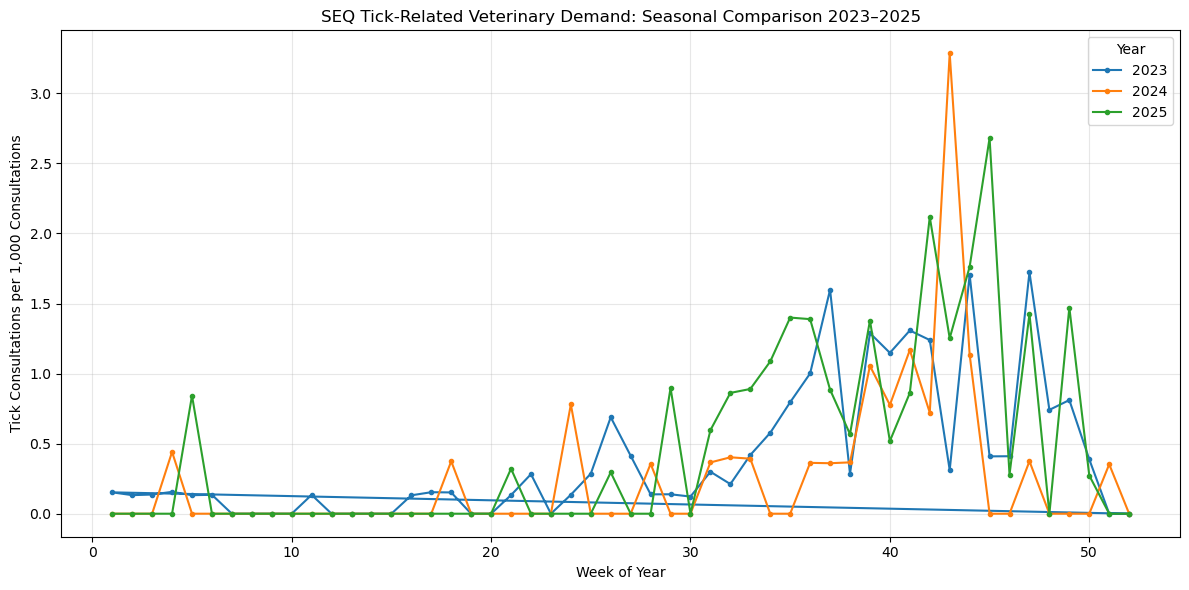

In [58]:
# ============================================================
# STEP 48 — SEASONAL PEAK COMPARISON PLOT
# ============================================================

plt.figure(figsize=(12, 6))

for year in [2023, 2024, 2025]:

    year_data = season_compare[
        season_compare["Year"] == year
    ]

    plt.plot(
        year_data["Week_of_Year"],
        year_data["Tick_per_1000"],
        marker="o",
        markersize=3,
        label=str(year)
    )

plt.xlabel("Week of Year")
plt.ylabel("Tick Consultations per 1,000 Consultations")
plt.title(
    "SEQ Tick-Related Veterinary Demand: "
    "Seasonal Comparison 2023–2025"
)

plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [59]:
# ============================================================
# STEP 49 — JULY TO NOVEMBER COMPARISON
# ============================================================

peak_season = monthly_compare[
    monthly_compare["Month"].isin([7, 8, 9, 10, 11])
].copy()

month_names = {
    7: "Jul",
    8: "Aug",
    9: "Sep",
    10: "Oct",
    11: "Nov"
}

peak_season["Month_Name"] = (
    peak_season["Month"].map(month_names)
)

peak_table = peak_season.pivot(
    index="Month_Name",
    columns="Year",
    values="Tick_per_1000"
)

# Put months in chronological order
peak_table = peak_table.reindex(
    ["Jul", "Aug", "Sep", "Oct", "Nov"]
)

print("JULY–NOVEMBER TICK RATE PER 1,000")
display(peak_table.round(3))

JULY–NOVEMBER TICK RATE PER 1,000


Year,2023,2024,2025
Month_Name,,,
Jul,0.296,0.092,0.218
Aug,0.380,0.288,0.974
Sep,0.921,0.434,1.061
Oct,1.066,1.449,1.191
Nov,1.085,0.374,1.235


In [60]:
import os

for file in os.listdir("."):
    name = file.lower()

    if (
        "weather" in name
        or "climate" in name
        or "silo" in name
    ):
        print(file)

clinic_weather_map.csv
extended_tick_weather_2020_2026.csv
silo_temperature_baseline.csv
silo_weather_2020_2023.csv
silo_weather_jul_sep_2026.csv
vetiq_silo_daily_weather_clean.csv


In [61]:
# ============================================================
# STEP 50 — INSPECT OUR EXTENDED WEATHER DATA
# ============================================================

import pandas as pd

weather_ext = pd.read_csv(
    "extended_tick_weather_2020_2026.csv"
)

print("Shape:", weather_ext.shape)

print("\nColumns:")
print(weather_ext.columns.tolist())

print("\nFirst 5 rows:")
display(weather_ext.head())

print("\nData types:")
print(weather_ext.dtypes)

Shape: (81, 6)

Columns:
['Month', 'tick_count', 'max_temp', 'min_temp', 'rainfall', 'vp']

First 5 rows:


,Month,tick_count,max_temp,min_temp,rainfall,vp
0,2020-01-01,8,31.234705,21.879422,7.347275,24.440489
1,2020-02-01,13,29.913436,21.830916,12.896076,25.630440
2,2020-03-01,7,28.470523,19.190768,3.741713,21.851724
3,2020-04-01,2,28.330690,16.506207,0.622874,19.593793
4,2020-05-01,2,23.675417,12.569855,1.177308,14.563626



Data types:
Month          object
tick_count      int64
max_temp      float64
min_temp      float64
rainfall      float64
vp            float64
dtype: object


In [62]:
# ============================================================
# STEP 51 — CHECK WEATHER COVERAGE
# ============================================================

# Show possible date/location columns before we make
# any assumptions about the dataset structure.

for col in weather_ext.columns:

    if any(
        word in col.lower()
        for word in [
            "date",
            "year",
            "month",
            "clinic",
            "lat",
            "lon",
            "temp",
            "rain"
        ]
    ):
        print(col)

Month
max_temp
min_temp
rainfall


In [63]:
# ============================================================
# STEP 52 — INSPECT CLEAN DAILY SILO WEATHER
# ============================================================

weather_daily = pd.read_csv(
    "vetiq_silo_daily_weather_clean.csv"
)

print("Shape:", weather_daily.shape)

print("\nColumns:")
print(weather_daily.columns.tolist())

print("\nFirst 5 rows:")
display(weather_daily.head())

print("\nData types:")
print(weather_daily.dtypes)

Shape: (32683, 17)

Columns:
['latitude', 'longitude', 'YYYY-MM-DD', 'daily_rain', 'daily_rain_source', 'max_temp', 'max_temp_source', 'min_temp', 'min_temp_source', 'vp', 'vp_source', 'mslp', 'mslp_source', 'rh_tmax', 'rh_tmax_source', 'metadata', 'weather_location_id']

First 5 rows:


,latitude,longitude,YYYY-MM-DD,daily_rain,daily_rain_source,max_temp,max_temp_source,min_temp,min_temp_source,vp,vp_source,mslp,mslp_source,rh_tmax,rh_tmax_source,metadata,weather_location_id
0,-28.15,153.45,2023-07-01,0.0,25,20.3,25,5.0,25,11.5,25,1021.5,25,48.3,26,elevation= 28.3 m,Weather_01
1,-28.15,153.45,2023-07-02,0.0,25,20.6,25,10.9,25,11.2,25,1027.6,25,46.2,26,reference=RXNVMH,Weather_01
2,-28.15,153.45,2023-07-03,2.8,25,18.2,25,13.6,25,15.3,25,1028.9,25,73.2,26,extracted=20260902,Weather_01
3,-28.15,153.45,2023-07-04,4.8,25,20.3,25,13.7,25,17.9,25,1021.6,25,75.2,26,dataset=BoM Only,Weather_01
4,-28.15,153.45,2023-07-05,30.0,25,25.2,25,15.8,25,20.0,25,1015.5,25,62.4,26,Please read our web site for information about...,Weather_01



Data types:
latitude               float64
longitude              float64
YYYY-MM-DD              object
daily_rain             float64
daily_rain_source        int64
max_temp               float64
max_temp_source          int64
min_temp               float64
min_temp_source          int64
vp                     float64
vp_source                int64
mslp                   float64
mslp_source              int64
rh_tmax                float64
rh_tmax_source           int64
metadata                object
weather_location_id     object
dtype: object


In [64]:
# ============================================================
# STEP 53 — CHECK WEATHER DATA COVERAGE
# ============================================================

# Find likely date column
date_cols = [
    c for c in weather_daily.columns
    if "date" in c.lower()
]

print("Possible date columns:", date_cols)

# Clinic/location information
location_cols = [
    c for c in weather_daily.columns
    if any(
        x in c.lower()
        for x in ["clinic", "lat", "lon", "suburb", "location"]
    )
]

print("Possible location columns:", location_cols)

Possible date columns: []
Possible location columns: ['latitude', 'longitude', 'weather_location_id']


In [65]:
# ============================================================
# STEP 54 — INSPECT CLINIC-WEATHER MAPPING
# ============================================================

clinic_weather_map = pd.read_csv(
    "clinic_weather_map.csv"
)

print("Shape:", clinic_weather_map.shape)

print("\nColumns:")
print(clinic_weather_map.columns.tolist())

display(clinic_weather_map.head(10))

Shape: (34, 8)

Columns:
['ClinicPseudonym', 'SuburbName', 'PostCode', 'longitude', 'latitude', 'silo_latitude', 'silo_longitude', 'weather_location_id']


,ClinicPseudonym,SuburbName,PostCode,longitude,latitude,silo_latitude,silo_longitude,weather_location_id
0,Clinic_54,Beaudesert,4285,153.000123,-27.988746,-28.00,153.00,Weather_03
1,Clinic_03,Augustine Heights,4300,152.878986,-27.662126,-27.65,152.90,Weather_12
2,Clinic_07,North MacLean,4280,152.997760,-27.767671,-27.75,153.00,Weather_08
3,Clinic_20,North Toowoomba,4350,151.955125,-27.546364,-27.55,151.95,Weather_16
4,Clinic_04,Redbank Plains,4301,152.851792,-27.653462,-27.65,152.85,Weather_11
5,Clinic_02,Yeppoon,4703,150.738674,-23.124600,-23.10,150.75,Weather_26
6,Clinic_33,Trinity Beach,4879,145.693900,-16.793513,-16.80,145.70,Weather_29
7,Clinic_05,Springfield,4300,152.911615,-27.654506,-27.65,152.90,Weather_12
8,Clinic_17,Flagstone,4280,152.948422,-27.811715,-27.80,152.95,Weather_07
9,Clinic_14,Jimboomba,4280,153.047160,-27.837701,-27.85,153.05,Weather_06


In [66]:
# ============================================================
# STEP 55 — PREPARE WEATHER DATA AND CLINIC MAPPING
# ============================================================

# Parse weather date
weather_daily["Date"] = pd.to_datetime(
    weather_daily["YYYY-MM-DD"],
    errors="coerce"
)

# Convert Clinic_17 -> 17 etc.
clinic_weather_map["ClinicID"] = pd.to_numeric(
    clinic_weather_map["ClinicPseudonym"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False),
    errors="coerce"
).astype("Int64")


# Check coverage of OUR 22 SEQ clinics
weather_map_seq = clinic_weather_map[
    clinic_weather_map["ClinicID"].isin(seq_clinic_ids)
].copy()

mapped_ids = set(
    weather_map_seq["ClinicID"]
    .dropna()
    .astype(int)
)

missing_weather_clinics = sorted(
    set(seq_clinic_ids) - mapped_ids
)

print("SEQ clinics:", len(seq_clinic_ids))
print("SEQ clinics with weather mapping:", len(mapped_ids))
print("Missing weather mappings:", missing_weather_clinics)

print(
    "\nWeather period:",
    weather_daily["Date"].min(),
    "to",
    weather_daily["Date"].max()
)

print(
    "Weather locations:",
    weather_daily["weather_location_id"].nunique()
)

SEQ clinics: 22
SEQ clinics with weather mapping: 5
Missing weather mappings: [8, 96, 99, 101, 102, 104, 105, 107, 108, 109, 112, 130, 136, 138, 241, 329, 338]

Weather period: 2023-07-01 00:00:00 to 2026-07-31 00:00:00
Weather locations: 29


In [67]:
# ============================================================
# STEP 56 — MATCH OUR SEQ CLINICS TO DAILY WEATHER
# ============================================================

seq_weather_daily = weather_map_seq[
    ["ClinicID", "weather_location_id"]
].merge(
    weather_daily,
    on="weather_location_id",
    how="inner"
)

weather_coverage = (
    seq_weather_daily
    .groupby("ClinicID")
    .agg(
        First_Date=("Date", "min"),
        Last_Date=("Date", "max"),
        Days=("Date", "nunique"),
        Weather_Location=("weather_location_id", "first")
    )
    .reset_index()
)

display(weather_coverage)

print("\nClinics with actual weather data:",
      seq_weather_daily["ClinicID"].nunique())

print("Matched daily weather rows:",
      len(seq_weather_daily))

,ClinicID,First_Date,Last_Date,Days,Weather_Location
0,15,2023-07-01,2026-07-31,1127,Weather_02
1,17,2023-07-01,2026-07-31,1127,Weather_07
2,18,2023-07-01,2026-07-31,1127,Weather_10
3,21,2023-07-01,2026-07-31,1127,Weather_04
4,22,2023-07-01,2026-07-31,1127,Weather_17



Clinics with actual weather data: 5
Matched daily weather rows: 5635


In [68]:
# ============================================================
# STEP 57 — INSPECT HISTORICAL SILO WEATHER
# ============================================================

weather_old = pd.read_csv("silo_weather_2020_2023.csv")

print("Shape:", weather_old.shape)
print("\nColumns:", weather_old.columns.tolist())

display(weather_old.head(3))

print("\nData types:")
print(weather_old.dtypes)

Shape: (37932, 15)

Columns: ['latitude', 'longitude', 'YYYY-MM-DD', 'daily_rain', 'daily_rain_source', 'max_temp', 'max_temp_source', 'min_temp', 'min_temp_source', 'vp', 'vp_source', 'metadata', 'weather_location_id', 'silo_latitude', 'silo_longitude']


,latitude,longitude,YYYY-MM-DD,daily_rain,daily_rain_source,max_temp,max_temp_source,min_temp,min_temp_source,vp,vp_source,metadata,weather_location_id,silo_latitude,silo_longitude
0,-28.15,153.45,2020-01-01,0.0,25,29.8,25,20.1,25,21.9,25,elevation= 28.3 m,Weather_01,-28.15,153.45
1,-28.15,153.45,2020-01-02,0.0,25,29.9,25,19.8,25,23.2,25,reference=RXNV,Weather_01,-28.15,153.45
2,-28.15,153.45,2020-01-03,0.0,25,29.9,25,18.9,25,22.3,25,extracted=20261001,Weather_01,-28.15,153.45



Data types:
latitude               float64
longitude              float64
YYYY-MM-DD              object
daily_rain             float64
daily_rain_source        int64
max_temp               float64
max_temp_source          int64
min_temp               float64
min_temp_source          int64
vp                     float64
vp_source                int64
metadata                object
weather_location_id     object
silo_latitude          float64
silo_longitude         float64
dtype: object


In [69]:
# ============================================================
# STEP 58 — INSPECT CLINIC-WEATHER MAPPING
# ============================================================

display(
    clinic_weather_map[
        [
            "ClinicPseudonym",
            "ClinicID",
            "SuburbName",
            "weather_location_id"
        ]
    ].sort_values("ClinicID")
)

print(
    "\nMapped ClinicIDs:",
    sorted(clinic_weather_map["ClinicID"].dropna().astype(int).unique())
)

,ClinicPseudonym,ClinicID,SuburbName,weather_location_id
27,Clinic_01,1,Deception Bay,Weather_23
5,Clinic_02,2,Yeppoon,Weather_26
1,Clinic_03,3,Augustine Heights,Weather_12
4,Clinic_04,4,Redbank Plains,Weather_11
7,Clinic_05,5,Springfield,Weather_12
15,Clinic_06,6,Greenbank,Weather_09
2,Clinic_07,7,North MacLean,Weather_08
32,Clinic_10,10,Currumbin Waters,Weather_01
18,Clinic_11,11,Kuraby,Weather_14
13,Clinic_12,12,Bardon,Weather_18



Mapped ClinicIDs: [1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 25, 26, 27, 28, 30, 31, 32, 33, 35, 47, 52, 54, 58, 59]


In [70]:
# ============================================================
# STEP 59 — COMBINE HISTORICAL AND RECENT SILO WEATHER
# ============================================================

weather_cols = [
    "weather_location_id",
    "YYYY-MM-DD",
    "max_temp",
    "min_temp",
    "daily_rain",
    "vp"
]

# Keep only the columns needed
old = weather_old[weather_cols].copy()
recent = weather_daily[weather_cols].copy()

# Combine both datasets
weather_combined = pd.concat(
    [old, recent],
    ignore_index=True
)

# Parse dates
weather_combined["Date"] = pd.to_datetime(
    weather_combined["YYYY-MM-DD"],
    errors="coerce"
)

# Remove duplicate weather-location/date records
weather_combined = weather_combined.drop_duplicates(
    subset=["weather_location_id", "Date"],
    keep="last"
)

# Calculate daily average temperature
weather_combined["AvgTemp_C"] = (
    weather_combined["max_temp"] +
    weather_combined["min_temp"]
) / 2

print("Rows:", len(weather_combined))
print("Weather locations:",
      weather_combined["weather_location_id"].nunique())
print("Period:",
      weather_combined["Date"].min(),
      "to",
      weather_combined["Date"].max())

Rows: 69716
Weather locations: 29
Period: 2020-01-01 00:00:00 to 2026-07-31 00:00:00


In [71]:
# ============================================================
# STEP 60 — WEATHER COVERAGE BY YEAR
# ============================================================

weather_combined["Year"] = weather_combined["Date"].dt.year

coverage = (
    weather_combined
    .groupby("Year")
    .agg(
        Records=("Date", "size"),
        Locations=("weather_location_id", "nunique"),
        Days=("Date", "nunique")
    )
    .reset_index()
)

display(coverage)

print("\nMissing temperature values:")
print(weather_combined["AvgTemp_C"].isna().sum())

,Year,Records,Locations,Days
0,2020,10614,29,366
1,2021,10585,29,365
2,2022,10585,29,365
3,2023,10585,29,365
4,2024,10614,29,366
5,2025,10585,29,365
6,2026,6148,29,212



Missing temperature values:
0


In [72]:
# ============================================================
# STEP 61 — IDENTIFY SEQ WEATHER LOCATIONS
# ============================================================

# Inspect all mapped locations and their coordinates
seq_weather_locations = (
    clinic_weather_map[
        [
            "SuburbName",
            "weather_location_id",
            "silo_latitude",
            "silo_longitude"
        ]
    ]
    .drop_duplicates()
    .sort_values("weather_location_id")
)

display(seq_weather_locations)

print(
    "Unique mapped weather locations:",
    seq_weather_locations["weather_location_id"].nunique()
)

,SuburbName,weather_location_id,silo_latitude,silo_longitude
32,Currumbin Waters,Weather_01,-28.15,153.45
22,Miami,Weather_02,-28.05,153.45
0,Beaudesert,Weather_03,-28.00,153.00
23,Labrador,Weather_04,-27.95,153.40
28,Helensvale,Weather_05,-27.90,153.35
9,Jimboomba,Weather_06,-27.85,153.05
8,Flagstone,Weather_07,-27.80,152.95
2,North MacLean,Weather_08,-27.75,153.00
15,Greenbank,Weather_09,-27.70,152.95
25,Loganholme,Weather_10,-27.70,153.20


Unique mapped weather locations: 29


In [73]:
# ============================================================
# STEP 62 — SELECT SEQ WEATHER LOCATIONS
# ============================================================

# Exclude four northern Queensland locations
exclude_suburbs = [
    "Yeppoon",
    "Stratford",
    "Cairns City",
    "Trinity Beach"
]

seq_locations = seq_weather_locations[
    ~seq_weather_locations["SuburbName"].isin(exclude_suburbs)
]["weather_location_id"].unique()

# Keep only SEQ weather observations
weather_seq = weather_combined[
    weather_combined["weather_location_id"].isin(seq_locations)
].copy()

print("SEQ weather locations:", len(seq_locations))
print("Weather records:", len(weather_seq))
print(
    "Period:",
    weather_seq["Date"].min(),
    "to",
    weather_seq["Date"].max()
)

SEQ weather locations: 25
Weather records: 60100
Period: 2020-01-01 00:00:00 to 2026-07-31 00:00:00


In [74]:
# ============================================================
# STEP 63 — CREATE WEEKLY SEQ WEATHER
# ============================================================

# Average weather across SEQ locations each day
daily_seq = (
    weather_seq
    .groupby("Date", as_index=False)
    .agg(
        AvgTemp_C=("AvgTemp_C", "mean"),
        MaxTemp_C=("max_temp", "mean"),
        MinTemp_C=("min_temp", "mean"),
        Locations=("weather_location_id", "nunique")
    )
)

# Match the Sunday-ending weeks used in our tick data
daily_seq["Week_End"] = (
    daily_seq["Date"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

# Aggregate daily temperatures into weekly averages
weekly_weather_seq = (
    daily_seq
    .groupby("Week_End", as_index=False)
    .agg(
        AvgTemp_C=("AvgTemp_C", "mean"),
        MaxTemp_C=("MaxTemp_C", "mean"),
        MinTemp_C=("MinTemp_C", "mean"),
        Weather_Days=("Date", "nunique"),
        Avg_Locations=("Locations", "mean")
    )
    .sort_values("Week_End")
)

print("Weekly weather rows:", len(weekly_weather_seq))
print(
    "Period:",
    weekly_weather_seq["Week_End"].min(),
    "to",
    weekly_weather_seq["Week_End"].max()
)

print(
    "Weather days/week:",
    weekly_weather_seq["Weather_Days"].min(),
    "to",
    weekly_weather_seq["Weather_Days"].max()
)

display(weekly_weather_seq.head())

Weekly weather rows: 344
Period: 2020-01-05 00:00:00 to 2026-08-02 00:00:00
Weather days/week: 5 to 7


,Week_End,AvgTemp_C,MaxTemp_C,MinTemp_C,Weather_Days,Avg_Locations
0,2020-01-05,25.585600,31.875200,19.296000,5,25.0
1,2020-01-12,26.403714,31.615429,21.192000,7,25.0
2,2020-01-19,24.955429,29.017143,20.893714,7,25.0
3,2020-01-26,27.800857,32.128000,23.473714,7,25.0
4,2020-02-02,26.807429,31.826286,21.788571,7,25.0


In [75]:
# ============================================================
# STEP 64 — MERGE WEEKLY WEATHER WITH TICK DEMAND
# ============================================================

seq_weather_analysis = seq_weekly.merge(
    weekly_weather_seq,
    on="Week_End",
    how="left"
).sort_values("Week_End")

# Temperature 1 and 2 weeks BEFORE tick consultations
seq_weather_analysis["Temp_Lag1"] = (
    seq_weather_analysis["AvgTemp_C"].shift(1)
)

seq_weather_analysis["Temp_Lag2"] = (
    seq_weather_analysis["AvgTemp_C"].shift(2)
)

print("Total weeks:", len(seq_weather_analysis))

print(
    "Weeks missing temperature:",
    seq_weather_analysis["AvgTemp_C"].isna().sum()
)

print(
    "Weeks missing lag-1 temperature:",
    seq_weather_analysis["Temp_Lag1"].isna().sum()
)

print(
    "Weeks missing lag-2 temperature:",
    seq_weather_analysis["Temp_Lag2"].isna().sum()
)

display(
    seq_weather_analysis[
        [
            "Week_End",
            "Tick_per_1000",
            "AvgTemp_C",
            "Temp_Lag1",
            "Temp_Lag2"
        ]
    ].head(8)
)

Total weeks: 252
Weeks missing temperature: 0
Weeks missing lag-1 temperature: 1
Weeks missing lag-2 temperature: 2


,Week_End,Tick_per_1000,AvgTemp_C,Temp_Lag1,Temp_Lag2
0,2021-10-03,1.010611,19.199714,NaN,NaN
1,2021-10-10,0.627648,21.157714,19.199714,NaN
2,2021-10-17,0.409836,20.654571,21.157714,19.199714
3,2021-10-24,0.826902,22.121714,20.654571,21.157714
4,2021-10-31,0.751315,23.661714,22.121714,20.654571
5,2021-11-07,0.702050,20.337143,23.661714,22.121714
6,2021-11-14,0.289813,23.442857,20.337143,23.661714
7,2021-11-21,0.137212,22.000857,23.442857,20.337143


In [76]:
# ============================================================
# STEP 65 — TEMPERATURE VS TICK DEMAND CORRELATIONS
# ============================================================

from scipy.stats import pearsonr, spearmanr

results = []

for lag, col in [
    (0, "AvgTemp_C"),
    (1, "Temp_Lag1"),
    (2, "Temp_Lag2")
]:

    # Keep only weeks with both measurements
    temp_df = seq_weather_analysis[
        [col, "Tick_per_1000"]
    ].dropna()

    pearson_r, pearson_p = pearsonr(
        temp_df[col],
        temp_df["Tick_per_1000"]
    )

    spearman_r, spearman_p = spearmanr(
        temp_df[col],
        temp_df["Tick_per_1000"]
    )

    results.append({
        "Lag_Weeks": lag,
        "Weeks": len(temp_df),
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_r": spearman_r,
        "Spearman_p": spearman_p
    })

temp_correlations = pd.DataFrame(results)

display(temp_correlations.round(4))

,Lag_Weeks,Weeks,Pearson_r,Pearson_p,Spearman_r,Spearman_p
0,0,252,-0.0910,0.1498,-0.2160,0.0006
1,1,251,-0.1284,0.0420,-0.2735,0.0000
2,2,250,-0.2015,0.0014,-0.3364,0.0000


In [77]:
'''Temperature and tick consultations may both increase during spring. We need to distinguish that shared seasonality from any additional relationship.
We'll subtract the average for each calendar week across years.'''

# ============================================================
# STEP 66 — SEASON-ADJUSTED TEMPERATURE CORRELATIONS
# ============================================================

season_df = seq_weather_analysis.copy()

# Calendar week number
season_df["Week_Num"] = (
    season_df["Week_End"]
    .dt.isocalendar()
    .week
    .astype(int)
)

# Remove the average seasonal pattern from tick demand
season_df["Tick_Anomaly"] = (
    season_df["Tick_per_1000"]
    - season_df.groupby("Week_Num")["Tick_per_1000"].transform("mean")
)

adjusted_results = []

for lag, col in [
    (0, "AvgTemp_C"),
    (1, "Temp_Lag1"),
    (2, "Temp_Lag2")
]:

    # Remove seasonal average from each temperature variable
    anomaly_col = f"{col}_Anomaly"

    season_df[anomaly_col] = (
        season_df[col]
        - season_df.groupby("Week_Num")[col].transform("mean")
    )

    valid = season_df[
        [anomaly_col, "Tick_Anomaly"]
    ].dropna()

    r, p = pearsonr(
        valid[anomaly_col],
        valid["Tick_Anomaly"]
    )

    adjusted_results.append({
        "Lag_Weeks": lag,
        "Weeks": len(valid),
        "Season_Adjusted_r": r,
        "p_value": p
    })

season_adjusted_corr = pd.DataFrame(adjusted_results)

display(season_adjusted_corr.round(4))

,Lag_Weeks,Weeks,Season_Adjusted_r,p_value
0,0,252,-0.1227,0.0518
1,1,251,-0.0467,0.4613
2,2,250,-0.0082,0.8972


In [78]:
# ============================================================
# STEP 67 — SAVE OUR WEATHER ANALYSIS
# ============================================================

seq_weather_analysis.to_csv(
    "our_seq_weekly_weather_2021_2026.csv",
    index=False
)

temp_correlations.to_csv(
    "our_temperature_correlations.csv",
    index=False
)

season_adjusted_corr.to_csv(
    "our_season_adjusted_correlations.csv",
    index=False
)

print("Weather analysis saved successfully.")

Weather analysis saved successfully.


In [79]:
# ============================================================
# STEP 68 — PREPARE WEEKLY FORECASTING DATA
# ============================================================

import pandas as pd
import numpy as np

model_df = seq_weather_analysis.copy()

model_df["Week_End"] = pd.to_datetime(model_df["Week_End"])
model_df = model_df.sort_values("Week_End").reset_index(drop=True)

# Target: tick consultations per 1,000 consultations
target = "Tick_per_1000"

# Previous tick-demand history
model_df["Tick_Lag1"] = model_df[target].shift(1)
model_df["Tick_Lag2"] = model_df[target].shift(2)
model_df["Tick_Lag4"] = model_df[target].shift(4)

# Historical average of previous 4 weeks
# shift(1) prevents using the current week's target
model_df["Tick_Roll4"] = (
    model_df[target]
    .shift(1)
    .rolling(4)
    .mean()
)

# Annual seasonality (approximately 52 weeks)
week_num = model_df["Week_End"].dt.isocalendar().week.astype(int)

model_df["Season_Sin"] = np.sin(2 * np.pi * week_num / 52.18)
model_df["Season_Cos"] = np.cos(2 * np.pi * week_num / 52.18)

# Baseline predictors
baseline_features = [
    "Tick_Lag1",
    "Tick_Lag2",
    "Tick_Lag4",
    "Tick_Roll4",
    "Season_Sin",
    "Season_Cos"
]

# Temperature model uses the same baseline plus lagged temperature
temperature_features = baseline_features + [
    "Temp_Lag1",
    "Temp_Lag2"
]

# Keep rows with all required predictors
model_ready = model_df.dropna(
    subset=temperature_features + [target]
).copy()

print("Total available weeks:", len(model_df))
print("Modelling weeks:", len(model_ready))
print("Period:", model_ready["Week_End"].min(),
      "to", model_ready["Week_End"].max())

print("\nBaseline features:", baseline_features)
print("Temperature features:", temperature_features)

Total available weeks: 252
Modelling weeks: 248
Period: 2021-10-31 00:00:00 to 2026-07-26 00:00:00

Baseline features: ['Tick_Lag1', 'Tick_Lag2', 'Tick_Lag4', 'Tick_Roll4', 'Season_Sin', 'Season_Cos']
Temperature features: ['Tick_Lag1', 'Tick_Lag2', 'Tick_Lag4', 'Tick_Roll4', 'Season_Sin', 'Season_Cos', 'Temp_Lag1', 'Temp_Lag2']


In [80]:
'''We'll use a chronological split: train through 2024 and test on 2025–July 2026. This gives both models exactly the same evaluation period.
We're using Ridge regression, which is straightforward, interpretable and suitable for comparing whether temperature adds value.'''

# ============================================================
# STEP 69 — BASELINE VS TEMPERATURE FORECAST
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Chronological train/test split
train = model_ready[
    model_ready["Week_End"] < "2025-01-01"
].copy()

test = model_ready[
    model_ready["Week_End"] >= "2025-01-01"
].copy()

def evaluate_model(features, model_name):

    # Standardize predictors, then fit Ridge regression
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    model.fit(
        train[features],
        train[target]
    )

    predictions = model.predict(test[features])

    # Tick consultation rates cannot be negative
    predictions = np.maximum(predictions, 0)

    mae = mean_absolute_error(test[target], predictions)
    rmse = np.sqrt(mean_squared_error(test[target], predictions))

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    }, predictions, model


baseline_result, baseline_pred, baseline_model = evaluate_model(
    baseline_features,
    "A: History + Seasonality"
)

temperature_result, temperature_pred, temperature_model = evaluate_model(
    temperature_features,
    "B: History + Seasonality + Temperature"
)

comparison = pd.DataFrame([
    baseline_result,
    temperature_result
])

print("TRAINING AND TESTING")
print("Training weeks:", len(train))
print("Testing weeks:", len(test))
print("Training period:", train["Week_End"].min(),
      "to", train["Week_End"].max())
print("Testing period:", test["Week_End"].min(),
      "to", test["Week_End"].max())

print("\nMODEL COMPARISON")
display(comparison.round(4))

print("\nTEMPERATURE IMPROVEMENT (%)")
print(
    "MAE:",
    round(
        (baseline_result["MAE"] - temperature_result["MAE"])
        / baseline_result["MAE"] * 100, 2
    )
)

print(
    "RMSE:",
    round(
        (baseline_result["RMSE"] - temperature_result["RMSE"])
        / baseline_result["RMSE"] * 100, 2
    )
)

TRAINING AND TESTING
Training weeks: 166
Testing weeks: 82
Training period: 2021-10-31 00:00:00 to 2024-12-29 00:00:00
Testing period: 2025-01-05 00:00:00 to 2026-07-26 00:00:00

MODEL COMPARISON


,Model,MAE,RMSE
0,A: History + Seasonality,0.2532,0.3986
1,B: History + Seasonality + Temperature,0.2529,0.3974



TEMPERATURE IMPROVEMENT (%)
MAE: 0.13
RMSE: 0.32


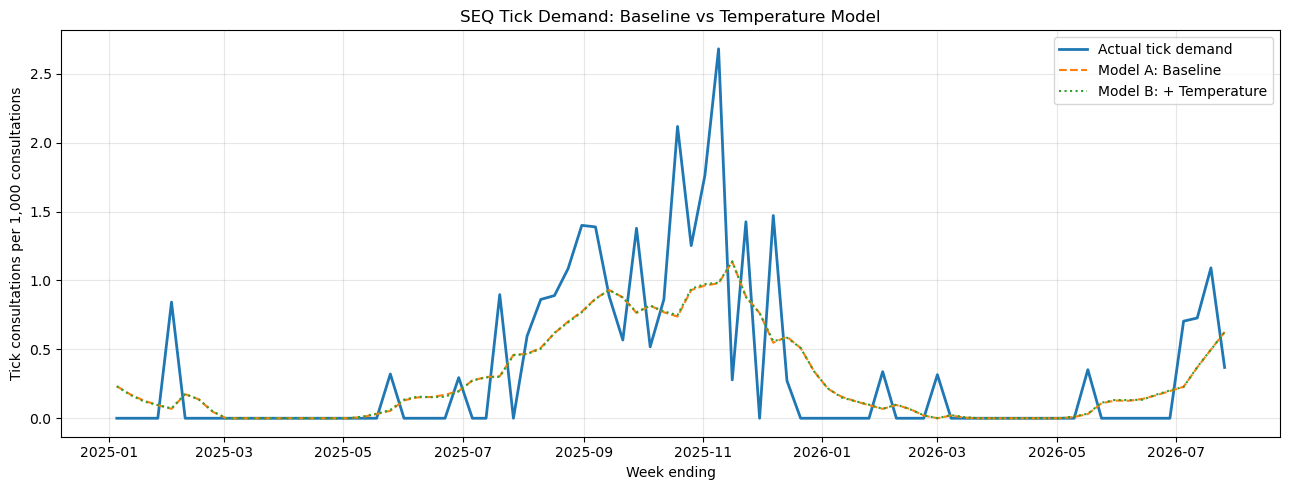

In [81]:
# ============================================================
# STEP 70 — VISUALISE MODEL PERFORMANCE
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))

plt.plot(
    test["Week_End"],
    test[target],
    label="Actual tick demand",
    linewidth=2
)

plt.plot(
    test["Week_End"],
    baseline_pred,
    label="Model A: Baseline",
    linestyle="--"
)

plt.plot(
    test["Week_End"],
    temperature_pred,
    label="Model B: + Temperature",
    linestyle=":"
)

plt.title("SEQ Tick Demand: Baseline vs Temperature Model")
plt.xlabel("Week ending")
plt.ylabel("Tick consultations per 1,000 consultations")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [84]:
# ============================================================
# STEP 71 — FIND NEW GOOGLE TRENDS BASKET FILES
# ============================================================

import os
import pandas as pd

for filename in os.listdir("."):
    if filename.lower().endswith(".csv") and any(
        word in filename.lower()
        for word in ["basket", "multitimeline", "trends", "google"]
    ):
        print(filename)

Basket_1.csv
Basket_2.csv
Basket_3.csv
multiTimeline-2.csv


In [85]:
# ============================================================
# STEP 72 — INSPECT GOOGLE TRENDS BASKETS
# ============================================================

basket_files = [
    "Basket_1.csv",
    "Basket_2.csv",
    "Basket_3.csv"
]

for filename in basket_files:

    print("\n" + "=" * 50)
    print("FILE:", filename)

    # Read raw lines to identify Google Trends headers
    with open(filename, "r", encoding="utf-8-sig") as f:
        for i in range(7):
            line = f.readline()
            if not line:
                break
            print(f"Line {i + 1}: {line.strip()}")

    # Read as a dataframe for initial inspection
    df = pd.read_csv(filename, header=None, nrows=8)

    print("\nPreview:")
    display(df)


FILE: Basket_1.csv
Line 1: "Time","tick","tick bite","tick paralysis","paralysis tick","tick symptoms"
Line 2: "2019-12-01",42,2,3,3,1
Line 3: "2020-01-01",45,2,3,3,2
Line 4: "2020-02-01",44,1,2,2,1
Line 5: "2020-03-01",47,1,1,1,1
Line 6: "2020-04-01",53,1,1,1,1
Line 7: "2020-05-01",49,1,1,1,1

Preview:


,0,1,2,3,4,5
0,Time,tick,tick bite,tick paralysis,paralysis tick,tick symptoms
1,2019-12-01,42,2,3,3,1
2,2020-01-01,45,2,3,3,2
3,2020-02-01,44,1,2,2,1
4,2020-03-01,47,1,1,1,1
5,2020-04-01,53,1,1,1,1
6,2020-05-01,49,1,1,1,1
7,2020-06-01,49,2,2,1,1



FILE: Basket_2.csv
Line 1: "Time","tick","tick treatment","tick removal","tick prevention","tick on dog"
Line 2: "2019-12-01",42,2,0,1,1
Line 3: "2020-01-01",45,2,0,0,1
Line 4: "2020-02-01",44,2,0,1,1
Line 5: "2020-03-01",46,1,0,0,1
Line 6: "2020-04-01",53,2,0,0,0
Line 7: "2020-05-01",49,2,0,0,1

Preview:


,0,1,2,3,4,5
0,Time,tick,tick treatment,tick removal,tick prevention,tick on dog
1,2019-12-01,42,2,0,1,1
2,2020-01-01,45,2,0,0,1
3,2020-02-01,44,2,0,1,1
4,2020-03-01,46,1,0,0,1
5,2020-04-01,53,2,0,0,0
6,2020-05-01,49,2,0,0,1
7,2020-06-01,49,1,0,0,1



FILE: Basket_3.csv
Line 1: "Time","tick","NexGard","NexGard Spectra","NexGard tick","NexGard for dogs"
Line 2: "2019-12-01",42,9,6,0,0
Line 3: "2020-01-01",45,8,6,0,1
Line 4: "2020-02-01",44,9,7,0,1
Line 5: "2020-03-01",46,9,7,0,1
Line 6: "2020-04-01",53,10,8,0,1
Line 7: "2020-05-01",49,8,6,0,0

Preview:


,0,1,2,3,4,5
0,Time,tick,NexGard,NexGard Spectra,NexGard tick,NexGard for dogs
1,2019-12-01,42,9,6,0,0
2,2020-01-01,45,8,6,0,1
3,2020-02-01,44,9,7,0,1
4,2020-03-01,46,9,7,0,1
5,2020-04-01,53,10,8,0,1
6,2020-05-01,49,8,6,0,0
7,2020-06-01,49,8,6,0,1


In [86]:
# ============================================================
# STEP 73 — LOAD AND VALIDATE GOOGLE TRENDS BASKETS
# ============================================================

baskets = {}

for i in [1, 2, 3]:

    df = pd.read_csv(f"Basket_{i}.csv")

    df["Time"] = pd.to_datetime(
        df["Time"],
        errors="coerce"
    )

    # Convert search indices to numeric values
    for col in df.columns:
        if col != "Time":
            df[col] = pd.to_numeric(df[col], errors="coerce")

    baskets[i] = df.sort_values("Time").reset_index(drop=True)

    print(f"\nBASKET {i}")
    print("Rows:", len(df))
    print("Period:", df["Time"].min(), "to", df["Time"].max())
    print("Columns:", df.columns.tolist())
    print("Missing values:", df.isna().sum().sum())


# Check whether the common anchor has identical values
anchor_check = baskets[1][["Time", "tick"]].rename(
    columns={"tick": "tick_1"}
)

for i in [2, 3]:
    anchor_check = anchor_check.merge(
        baskets[i][["Time", "tick"]].rename(
            columns={"tick": f"tick_{i}"}
        ),
        on="Time",
        how="outer"
    )

print("\nCOMMON ANCHOR COMPARISON")
display(anchor_check.head())

print(
    "Basket 1 vs 2 identical:",
    anchor_check["tick_1"].equals(anchor_check["tick_2"])
)
print(
    "Basket 1 vs 3 identical:",
    anchor_check["tick_1"].equals(anchor_check["tick_3"])
)


BASKET 1
Rows: 83
Period: 2019-12-01 00:00:00 to 2026-10-01 00:00:00
Columns: ['Time', 'tick', 'tick bite', 'tick paralysis', 'paralysis tick', 'tick symptoms']
Missing values: 0

BASKET 2
Rows: 83
Period: 2019-12-01 00:00:00 to 2026-10-01 00:00:00
Columns: ['Time', 'tick', 'tick treatment', 'tick removal', 'tick prevention', 'tick on dog']
Missing values: 0

BASKET 3
Rows: 83
Period: 2019-12-01 00:00:00 to 2026-10-01 00:00:00
Columns: ['Time', 'tick', 'NexGard', 'NexGard Spectra', 'NexGard tick', 'NexGard for dogs']
Missing values: 0

COMMON ANCHOR COMPARISON


,Time,tick_1,tick_2,tick_3
0,2019-12-01,42,42,42
1,2020-01-01,45,45,45
2,2020-02-01,44,44,44
3,2020-03-01,47,46,46
4,2020-04-01,53,53,53


Basket 1 vs 2 identical: False
Basket 1 vs 3 identical: False


In [87]:
# ============================================================
# STEP 74 — SEARCH TERM VARIATION
# ============================================================

for i, df in baskets.items():

    print(f"\nBASKET {i}")

    summary = pd.DataFrame({
        "Mean": df.drop(columns="Time").mean(),
        "Std": df.drop(columns="Time").std(),
        "Zero_Percent": (
            df.drop(columns="Time").eq(0).mean() * 100
        )
    })

    display(summary.round(2))


BASKET 1


,Mean,Std,Zero_Percent
tick,53.78,10.90,0.0
tick bite,2.46,1.21,0.0
tick paralysis,3.10,1.89,0.0
paralysis tick,3.05,1.99,0.0
tick symptoms,1.42,0.57,1.2



BASKET 2


,Mean,Std,Zero_Percent
tick,53.95,10.82,0.00
tick treatment,2.83,1.15,0.00
tick removal,0.66,0.59,39.76
tick prevention,0.58,0.61,48.19
tick on dog,0.92,0.45,14.46



BASKET 3


,Mean,Std,Zero_Percent
tick,53.95,10.82,0.00
NexGard,10.16,1.55,0.00
NexGard Spectra,8.31,1.43,0.00
NexGard tick,0.31,0.47,68.67
NexGard for dogs,1.04,0.43,7.23


In [88]:
'''
We'll use:
- Occurrence: tick bites, paralysis, symptoms and ticks on dogs.
- Prevention/treatment: treatment, removal, prevention and NexGard searches.
- Combined: all 13 terms, comparable to Sree's approach.
We'll standardise each search term before averaging, so high-volume terms don't dominate.
'''

# ============================================================
# STEP 75 — BUILD THREE GOOGLE TRENDS INDICES
# ============================================================

# 1. Combine all baskets
# Keep only one copy of the common "tick" anchor.

trends = baskets[1].copy()

for i in [2, 3]:
    trends = trends.merge(
        baskets[i].drop(columns="tick"),
        on="Time",
        how="inner"
    )

# 2. Define search groups

occurrence_terms = [
    "tick bite",
    "tick paralysis",
    "paralysis tick",
    "tick symptoms",
    "tick on dog"
]

prevention_terms = [
    "tick treatment",
    "tick removal",
    "tick prevention",
    "NexGard",
    "NexGard Spectra",
    "NexGard tick",
    "NexGard for dogs"
]

all_terms = ["tick"] + occurrence_terms + prevention_terms

# 3. Standardise each term using its mean and standard deviation

trends_z = trends[["Time"]].copy()

for col in all_terms:
    std = trends[col].std()

    trends_z[col] = (
        (trends[col] - trends[col].mean()) / std
        if std > 0 else 0.0
    )

# 4. Create three indices

trends_z["GT_Occurrence"] = trends_z[
    occurrence_terms
].mean(axis=1)

trends_z["GT_Prevention"] = trends_z[
    prevention_terms
].mean(axis=1)

trends_z["GT_Combined"] = trends_z[
    all_terms
].mean(axis=1)

# 5. Display results

indices = [
    "GT_Occurrence",
    "GT_Prevention",
    "GT_Combined"
]

print("Months:", len(trends_z))
print("Period:", trends_z["Time"].min(),
      "to", trends_z["Time"].max())

print("\nIndex summary:")
display(trends_z[indices].describe().round(3))

print("\nCorrelation between indices:")
display(trends_z[indices].corr().round(3))

print("\nFirst five months:")
display(trends_z[["Time"] + indices].head())

Months: 83
Period: 2019-12-01 00:00:00 to 2026-10-01 00:00:00

Index summary:


,GT_Occurrence,GT_Prevention,GT_Combined
count,83.000,83.000,83.000
mean,0.000,-0.000,0.000
std,0.852,0.724,0.739
min,-1.227,-1.273,-1.056
25%,-0.674,-0.511,-0.576
50%,-0.202,-0.144,-0.205
75%,0.523,0.385,0.462
max,2.314,1.614,1.787



Correlation between indices:


,GT_Occurrence,GT_Prevention,GT_Combined
GT_Occurrence,1.000,0.797,0.941
GT_Prevention,0.797,1.000,0.950
GT_Combined,0.941,0.950,1.000



First five months:


,Time,GT_Occurrence,GT_Prevention,GT_Combined
0,2019-12-01,-0.201928,-0.945710,-0.670067
1,2020-01-01,0.151619,-0.937898,-0.508705
2,2020-02-01,-0.573251,-0.510634,-0.564494
3,2020-03-01,-0.779659,-0.870562,-0.816513
4,2020-04-01,-1.226741,-0.553850,-0.775579


In [89]:
# ============================================================
# STEP 76 — MERGE LAGGED GOOGLE TRENDS WITH WEEKLY DATA
# ============================================================

# Copy existing weekly modelling dataset
model_gt = model_df.copy()

# Identify calendar month for each week
model_gt["Month"] = (
    model_gt["Week_End"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Prepare monthly Google Trends indices
gt_monthly = trends_z[
    ["Time", "GT_Occurrence", "GT_Prevention", "GT_Combined"]
].copy()

gt_monthly = gt_monthly.rename(columns={"Time": "Month"})

# Shift indices by one month
for col in ["GT_Occurrence", "GT_Prevention", "GT_Combined"]:
    gt_monthly[col + "_Lag1M"] = gt_monthly[col].shift(1)

# Merge into weekly dataset
model_gt = model_gt.merge(
    gt_monthly[
        ["Month",
         "GT_Occurrence_Lag1M",
         "GT_Prevention_Lag1M",
         "GT_Combined_Lag1M"]
    ],
    on="Month",
    how="left"
)

# Validate merge
print("Total weeks:", len(model_gt))
print("Date range:",
      model_gt["Week_End"].min(),
      "to",
      model_gt["Week_End"].max())

print("\nMissing values:")
print(model_gt[
    ["GT_Occurrence_Lag1M",
     "GT_Prevention_Lag1M",
     "GT_Combined_Lag1M"]
].isna().sum())

display(model_gt[
    ["Week_End", "Tick_per_1000",
     "GT_Occurrence_Lag1M",
     "GT_Prevention_Lag1M",
     "GT_Combined_Lag1M"]
].head())

Total weeks: 252
Date range: 2021-10-03 00:00:00 to 2026-07-26 00:00:00

Missing values:
GT_Occurrence_Lag1M    0
GT_Prevention_Lag1M    0
GT_Combined_Lag1M      0
dtype: int64


,Week_End,Tick_per_1000,GT_Occurrence_Lag1M,GT_Prevention_Lag1M,GT_Combined_Lag1M
0,2021-10-03,1.010611,0.788502,0.354309,0.467347
1,2021-10-10,0.627648,0.788502,0.354309,0.467347
2,2021-10-17,0.409836,0.788502,0.354309,0.467347
3,2021-10-24,0.826902,0.788502,0.354309,0.467347
4,2021-10-31,0.751315,0.788502,0.354309,0.467347


In [90]:
'''these are one-week-ahead historical predictions using observed lagged consultations'''

# ============================================================
# STEP 77 — COMPARE GOOGLE TRENDS FORECASTING MODELS
# ============================================================

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Recalculate Google Trends indices using training data only
# Training period ends December 2024.

gt_train_mask = trends["Time"] < "2025-01-01"

trends_train_z = trends[["Time"]].copy()

for col in all_terms:
    train_mean = trends.loc[gt_train_mask, col].mean()
    train_std = trends.loc[gt_train_mask, col].std()

    trends_train_z[col] = (
        (trends[col] - train_mean) / train_std
        if train_std > 0 else 0.0
    )

groups = {
    "Occurrence": occurrence_terms,
    "Prevention": prevention_terms,
    "Combined": all_terms
}

for name, cols in groups.items():
    trends_train_z[f"GT_{name}"] = trends_train_z[cols].mean(axis=1)

# 2. Shift monthly indices by one month

gt_revised = trends_train_z[
    ["Time", "GT_Occurrence", "GT_Prevention", "GT_Combined"]
].rename(columns={"Time": "Month"}).copy()

for name in groups:
    gt_revised[f"GT_{name}_Lag1M"] = (
        gt_revised[f"GT_{name}"].shift(1)
    )

# 3. Merge with existing weekly model dataset

model_compare = model_df.copy()

model_compare["Month"] = (
    model_compare["Week_End"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

model_compare = model_compare.merge(
    gt_revised[
        ["Month"] + [f"GT_{name}_Lag1M" for name in groups]
    ],
    on="Month",
    how="left"
)

# 4. Define six forecasting models

feature_sets = {
    "A: Baseline": baseline_features,
    "B: Baseline + Temperature": temperature_features,
    "C: Baseline + Occurrence": baseline_features + ["GT_Occurrence_Lag1M"],
    "D: Baseline + Prevention": baseline_features + ["GT_Prevention_Lag1M"],
    "E: Baseline + Combined": baseline_features + ["GT_Combined_Lag1M"],
    "F: Baseline + Temp + Combined": temperature_features + ["GT_Combined_Lag1M"]
}

# Use identical weeks for all models
required_features = list(set(
    feature for features in feature_sets.values()
    for feature in features
))

ready_compare = model_compare.dropna(
    subset=required_features + [target]
).copy()

train_compare = ready_compare[
    ready_compare["Week_End"] < "2025-01-01"
]

test_compare = ready_compare[
    ready_compare["Week_End"] >= "2025-01-01"
]

# 5. Train and evaluate

comparison_results = []
comparison_predictions = {}

for name, features in feature_sets.items():

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    model.fit(train_compare[features], train_compare[target])

    predictions = np.maximum(
        model.predict(test_compare[features]), 0
    )

    comparison_predictions[name] = predictions

    comparison_results.append({
        "Model": name,
        "MAE": mean_absolute_error(test_compare[target], predictions),
        "RMSE": np.sqrt(
            mean_squared_error(test_compare[target], predictions)
        )
    })

comparison_results = pd.DataFrame(comparison_results)

# 6. Calculate improvement over baseline

baseline_mae = comparison_results.loc[0, "MAE"]
baseline_rmse = comparison_results.loc[0, "RMSE"]

comparison_results["MAE_Improvement_%"] = (
    (baseline_mae - comparison_results["MAE"])
    / baseline_mae * 100
)

comparison_results["RMSE_Improvement_%"] = (
    (baseline_rmse - comparison_results["RMSE"])
    / baseline_rmse * 100
)

print("Training weeks:", len(train_compare))
print("Testing weeks:", len(test_compare))
print("Test period:",
      test_compare["Week_End"].min(),
      "to",
      test_compare["Week_End"].max())

display(comparison_results.round(4))

Training weeks: 166
Testing weeks: 82
Test period: 2025-01-05 00:00:00 to 2026-07-26 00:00:00


,Model,MAE,RMSE,MAE_Improvement_%,RMSE_Improvement_%
0,A: Baseline,0.2532,0.3986,0.0000,0.0000
1,B: Baseline + Temperature,0.2529,0.3974,0.1335,0.3183
2,C: Baseline + Occurrence,0.2695,0.4121,-6.4249,-3.3628
3,D: Baseline + Prevention,0.2552,0.3971,-0.7958,0.3861
4,E: Baseline + Combined,0.2632,0.4047,-3.9381,-1.5169
5,F: Baseline + Temp + Combined,0.2629,0.4054,-3.8174,-1.6933


In [91]:
# ============================================================
# STEP 78 — PEAK-SEASON FORECAST PERFORMANCE
# ============================================================

# Select August–November 2025 from our existing test data
peak_mask = (
    (test_compare["Week_End"] >= "2025-08-01") &
    (test_compare["Week_End"] <= "2025-11-30")
)

peak_actual = test_compare.loc[
    peak_mask, target
]

peak_results = []

for name, predictions in comparison_predictions.items():

    # Select predictions corresponding to peak-season weeks
    peak_pred = predictions[peak_mask.to_numpy()]

    peak_results.append({
        "Model": name,
        "MAE": mean_absolute_error(peak_actual, peak_pred),
        "RMSE": np.sqrt(
            mean_squared_error(peak_actual, peak_pred)
        )
    })

peak_results = pd.DataFrame(peak_results)

# Calculate improvements relative to baseline
base_mae = peak_results.loc[0, "MAE"]
base_rmse = peak_results.loc[0, "RMSE"]

peak_results["MAE_Improvement_%"] = (
    (base_mae - peak_results["MAE"]) / base_mae * 100
)

peak_results["RMSE_Improvement_%"] = (
    (base_rmse - peak_results["RMSE"]) / base_rmse * 100
)

print("Peak-season weeks:", peak_mask.sum())
print("Period: August–November 2025")

display(peak_results.round(4))

Peak-season weeks: 18
Period: August–November 2025


,Model,MAE,RMSE,MAE_Improvement_%,RMSE_Improvement_%
0,A: Baseline,0.5561,0.6973,0.0000,0.0000
1,B: Baseline + Temperature,0.5548,0.6953,0.2243,0.2815
2,C: Baseline + Occurrence,0.5611,0.7103,-0.8933,-1.8666
3,D: Baseline + Prevention,0.5454,0.6884,1.9230,1.2783
4,E: Baseline + Combined,0.5520,0.6974,0.7352,-0.0125
5,F: Baseline + Temp + Combined,0.5526,0.6990,0.6264,-0.2528


Forecast starts: 2026-08-02 00:00:00
Forecast ends: 2026-10-25 00:00:00
Total forecast weeks: 13

OCTOBER 2026 RIDGE FORECAST


,Week_End,Ridge_Forecast_per_1000
9,2026-10-04,0.809
10,2026-10-11,0.806
11,2026-10-18,0.797
12,2026-10-25,0.781



October peak forecast: 0.809 per 1,000 consultations


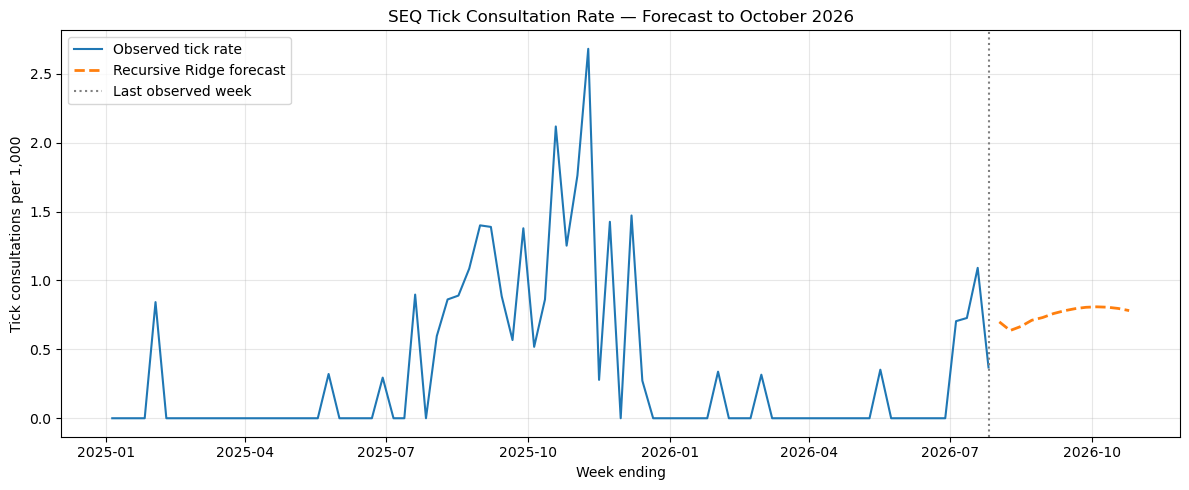

In [92]:
# ============================================================
# STEP 79 — RECURSIVE RIDGE FORECAST THROUGH OCTOBER 2026
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# 1. Use all available historical observations
forecast_data = model_df.sort_values("Week_End").copy()

forecast_train = forecast_data.dropna(
    subset=baseline_features + [target]
).copy()

# 2. Train the final baseline Ridge model
ridge_final = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10.0)
)

ridge_final.fit(
    forecast_train[baseline_features],
    forecast_train[target]
)

# 3. Store the latest observed tick rates
history = forecast_data[target].tolist()

last_date = forecast_data["Week_End"].max()

# Forecast every Sunday through October 2026
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(weeks=1),
    end="2026-10-31",
    freq="W-SUN"
)

forecast_rows = []

# 4. Generate recursive weekly predictions
for date in future_dates:

    week_num = date.isocalendar().week

    features = pd.DataFrame([{
        "Tick_Lag1": history[-1],
        "Tick_Lag2": history[-2],
        "Tick_Lag4": history[-4],

        # Mean of previous 4 observed/predicted weeks
        "Tick_Roll4": np.mean(history[-4:]),

        "Season_Sin": np.sin(
            2 * np.pi * week_num / 52.18
        ),
        "Season_Cos": np.cos(
            2 * np.pi * week_num / 52.18
        )
    }])

    # Predict consultation rate per 1,000
    prediction = max(
        float(ridge_final.predict(features[baseline_features])[0]),
        0
    )

    forecast_rows.append({
        "Week_End": date,
        "Ridge_Forecast_per_1000": prediction
    })

    # Add prediction so the next week can use it
    history.append(prediction)

ridge_forecast = pd.DataFrame(forecast_rows)

# 5. Display October forecasts
october_forecast = ridge_forecast[
    ridge_forecast["Week_End"].dt.month == 10
].copy()

print("Forecast starts:", ridge_forecast["Week_End"].min())
print("Forecast ends:", ridge_forecast["Week_End"].max())
print("Total forecast weeks:", len(ridge_forecast))

print("\nOCTOBER 2026 RIDGE FORECAST")
display(october_forecast.round(3))

print(
    "\nOctober peak forecast:",
    round(october_forecast["Ridge_Forecast_per_1000"].max(), 3),
    "per 1,000 consultations"
)

# 6. Visualise observed history and forecast
plt.figure(figsize=(12, 5))

recent_history = forecast_data[
    forecast_data["Week_End"] >= "2025-01-01"
]

plt.plot(
    recent_history["Week_End"],
    recent_history[target],
    label="Observed tick rate"
)

plt.plot(
    ridge_forecast["Week_End"],
    ridge_forecast["Ridge_Forecast_per_1000"],
    label="Recursive Ridge forecast",
    linestyle="--",
    linewidth=2
)

plt.axvline(
    last_date,
    linestyle=":",
    color="grey",
    label="Last observed week"
)

plt.title("SEQ Tick Consultation Rate — Forecast to October 2026")
plt.xlabel("Week ending")
plt.ylabel("Tick consultations per 1,000")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Save forecast
ridge_forecast.to_csv(
    "our_ridge_forecast_aug_oct_2026.csv",
    index=False
)

In [93]:
# ============================================================
# STEP 80 — HISTORICAL SEASONAL FORECAST
# ============================================================

# Use the weekly SEQ consultation rates
seasonal_data = seq_weekly.copy()

seasonal_data["Year"] = seasonal_data["Week_End"].dt.year
seasonal_data["ISO_Week"] = (
    seasonal_data["Week_End"].dt.isocalendar().week.astype(int)
)

# Historical reference years
historical = seasonal_data[
    seasonal_data["Year"].isin([2023, 2024, 2025])
].copy()

# Match future weeks by ISO week number
seasonal_forecast = october_forecast.copy()

seasonal_forecast["ISO_Week"] = (
    seasonal_forecast["Week_End"]
    .dt.isocalendar().week.astype(int)
)

seasonal_stats = (
    historical.groupby("ISO_Week")["Tick_per_1000"]
    .agg(
        Seasonal_Mean="mean",
        Seasonal_Median="median",
        Historical_Min="min",
        Historical_Max="max"
    )
    .reset_index()
)

seasonal_forecast = seasonal_forecast.merge(
    seasonal_stats,
    on="ISO_Week",
    how="left"
)

print("OCTOBER 2026 — RIDGE VS HISTORICAL SEASONAL FORECAST")

display(
    seasonal_forecast[
        [
            "Week_End",
            "Ridge_Forecast_per_1000",
            "Seasonal_Mean",
            "Seasonal_Median",
            "Historical_Min",
            "Historical_Max"
        ]
    ].round(3)
)

print("\nOctober seasonal peak:",
      round(seasonal_forecast["Seasonal_Mean"].max(), 3))

# Save results
seasonal_forecast.to_csv(
    "our_october_2026_ridge_vs_seasonal.csv",
    index=False
)

OCTOBER 2026 — RIDGE VS HISTORICAL SEASONAL FORECAST


,Week_End,Ridge_Forecast_per_1000,Seasonal_Mean,Seasonal_Median,Historical_Min,Historical_Max
0,2026-10-04,0.809,0.814,0.776,0.518,1.148
1,2026-10-11,0.806,1.112,1.168,0.862,1.308
2,2026-10-18,0.797,1.360,1.240,0.722,2.118
3,2026-10-25,0.781,1.616,1.253,0.311,3.285



October seasonal peak: 1.616


BACKTEST: AUGUST–OCTOBER 2025


,Model,MAE,RMSE
0,Ridge,0.4820,0.5984
1,Seasonal,0.4952,0.5980



OCTOBER 2025 — ACTUAL VS FORECAST


,Week_End,Actual,Ridge,Seasonal
9,2025-10-05,0.518,0.701,0.908
10,2025-10-12,0.862,0.702,1.259
11,2025-10-19,2.118,0.696,0.878
12,2025-10-26,1.253,0.685,1.707


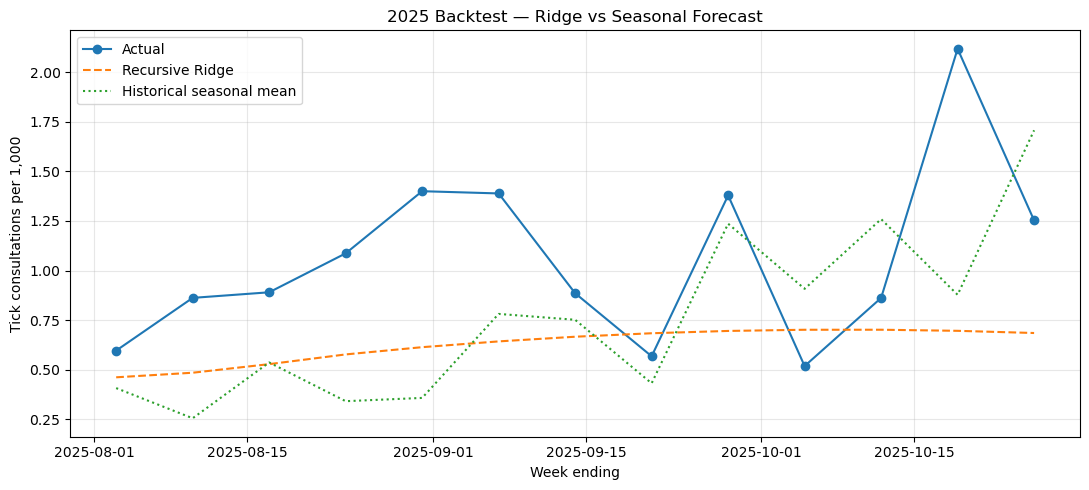

In [94]:
# ============================================================
# STEP 81 — MULTI-WEEK BACKTEST: AUGUST–OCTOBER 2025
# ============================================================

# 1. Train Ridge using data available through July 2025
cutoff = pd.Timestamp("2025-07-27")

backtest_train = model_df[
    model_df["Week_End"] <= cutoff
].dropna(subset=baseline_features + [target]).copy()

backtest_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10.0)
)

backtest_model.fit(
    backtest_train[baseline_features],
    backtest_train[target]
)

# 2. Recursive forecast through October 2025
history = model_df.loc[
    model_df["Week_End"] <= cutoff, target
].tolist()

future_weeks = pd.date_range(
    "2025-08-03", "2025-10-26", freq="W-SUN"
)

predictions = []

for date in future_weeks:

    week = date.isocalendar().week

    features = pd.DataFrame([{
        "Tick_Lag1": history[-1],
        "Tick_Lag2": history[-2],
        "Tick_Lag4": history[-4],
        "Tick_Roll4": np.mean(history[-4:]),
        "Season_Sin": np.sin(2*np.pi*week/52.18),
        "Season_Cos": np.cos(2*np.pi*week/52.18)
    }])

    pred = max(
        float(backtest_model.predict(
            features[baseline_features]
        )[0]),
        0
    )

    predictions.append(pred)
    history.append(pred)

# 3. Create comparison table
backtest = pd.DataFrame({
    "Week_End": future_weeks,
    "Ridge": predictions
})

# Actual consultation rates
backtest = backtest.merge(
    seq_weekly[["Week_End", "Tick_per_1000"]],
    on="Week_End",
    how="left"
).rename(columns={"Tick_per_1000": "Actual"})

# 4. Seasonal benchmark using ONLY 2022–2024
historical_bt = seq_weekly[
    seq_weekly["Week_End"].dt.year.isin([2022, 2023, 2024])
].copy()

historical_bt["ISO_Week"] = (
    historical_bt["Week_End"].dt.isocalendar().week.astype(int)
)

seasonal_means = (
    historical_bt.groupby("ISO_Week")["Tick_per_1000"]
    .mean()
)

backtest["ISO_Week"] = (
    backtest["Week_End"].dt.isocalendar().week.astype(int)
)

backtest["Seasonal"] = (
    backtest["ISO_Week"].map(seasonal_means)
)

# 5. Evaluate
results = []

for name in ["Ridge", "Seasonal"]:

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            backtest["Actual"], backtest[name]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            backtest["Actual"], backtest[name]
        ))
    })

print("BACKTEST: AUGUST–OCTOBER 2025")
display(pd.DataFrame(results).round(4))

print("\nOCTOBER 2025 — ACTUAL VS FORECAST")
display(
    backtest[
        backtest["Week_End"].dt.month == 10
    ][["Week_End", "Actual", "Ridge", "Seasonal"]].round(3)
)

# 6. Plot
plt.figure(figsize=(11, 5))

plt.plot(backtest["Week_End"], backtest["Actual"],
         label="Actual", marker="o")

plt.plot(backtest["Week_End"], backtest["Ridge"],
         label="Recursive Ridge", linestyle="--")

plt.plot(backtest["Week_End"], backtest["Seasonal"],
         label="Historical seasonal mean", linestyle=":")

plt.title("2025 Backtest — Ridge vs Seasonal Forecast")
plt.ylabel("Tick consultations per 1,000")
plt.xlabel("Week ending")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [95]:
# ============================================================
# STEP 82 — MULTI-YEAR AUGUST–OCTOBER BACKTEST
# ============================================================

backtest_results = []

for year in [2023, 2024, 2025]:

    cutoff = pd.Timestamp(f"{year}-07-31")
    future_weeks = pd.date_range(
        f"{year}-08-01",
        f"{year}-10-31",
        freq="W-SUN"
    )

    # Train Ridge using only information before August
    train = model_df[
        model_df["Week_End"] <= cutoff
    ].dropna(subset=baseline_features + [target])

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    model.fit(train[baseline_features], train[target])

    history = model_df.loc[
        model_df["Week_End"] <= cutoff, target
    ].tolist()

    ridge_preds = []

    for date in future_weeks:

        week = date.isocalendar().week

        features = pd.DataFrame([{
            "Tick_Lag1": history[-1],
            "Tick_Lag2": history[-2],
            "Tick_Lag4": history[-4],
            "Tick_Roll4": np.mean(history[-4:]),
            "Season_Sin": np.sin(2*np.pi*week/52.18),
            "Season_Cos": np.cos(2*np.pi*week/52.18)
        }])

        pred = max(
            float(model.predict(
                features[baseline_features]
            )[0]), 0
        )

        ridge_preds.append(pred)
        history.append(pred)

    bt = pd.DataFrame({
        "Week_End": future_weeks,
        "Ridge": ridge_preds
    })

    bt = bt.merge(
        seq_weekly[["Week_End", "Tick_per_1000"]],
        on="Week_End",
        how="left"
    ).rename(columns={"Tick_per_1000": "Actual"})

    # Seasonal benchmark: all earlier years only
    past = seq_weekly[
        seq_weekly["Week_End"].dt.year < year
    ].copy()

    past["ISO_Week"] = (
        past["Week_End"].dt.isocalendar().week.astype(int)
    )

    seasonal_mean = past.groupby(
        "ISO_Week"
    )["Tick_per_1000"].mean()

    bt["ISO_Week"] = (
        bt["Week_End"].dt.isocalendar().week.astype(int)
    )

    bt["Seasonal"] = bt["ISO_Week"].map(seasonal_mean)

    for method in ["Ridge", "Seasonal"]:

        valid = bt.dropna(subset=["Actual", method])

        backtest_results.append({
            "Year": year,
            "Model": method,
            "Weeks": len(valid),
            "MAE": mean_absolute_error(
                valid["Actual"], valid[method]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                valid["Actual"], valid[method]
            ))
        })

multi_year_results = pd.DataFrame(backtest_results)

print("MULTI-YEAR BACKTEST: AUGUST–OCTOBER")
display(multi_year_results.round(4))

print("\nAVERAGE PERFORMANCE")
display(
    multi_year_results.groupby("Model")[
        ["MAE", "RMSE"]
    ].mean().round(4)
)

MULTI-YEAR BACKTEST: AUGUST–OCTOBER


,Year,Model,Weeks,MAE,RMSE
0,2023,Ridge,13,0.3884,0.4706
1,2023,Seasonal,13,0.4101,0.5299
2,2024,Ridge,13,0.4406,0.7832
3,2024,Seasonal,13,0.4526,0.7528
4,2025,Ridge,13,0.4820,0.5984
5,2025,Seasonal,13,0.4604,0.5795



AVERAGE PERFORMANCE


,MAE,RMSE
Model,,
Ridge,0.437,0.6174
Seasonal,0.441,0.6207


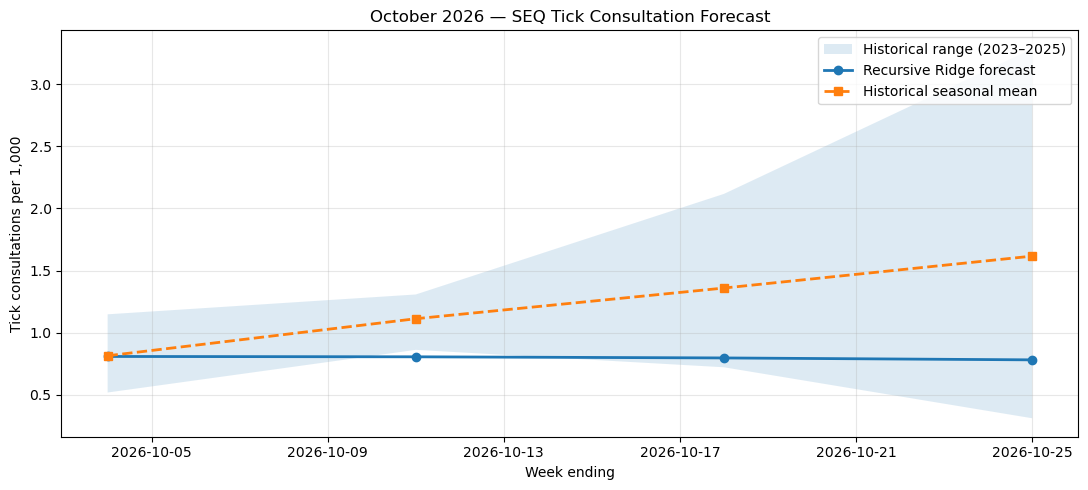

In [96]:
# ============================================================
# STEP 83 — OCTOBER 2026 FORECAST COMPARISON
# ============================================================

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))

dates = seasonal_forecast["Week_End"]

# Historical range
ax.fill_between(
    dates,
    seasonal_forecast["Historical_Min"],
    seasonal_forecast["Historical_Max"],
    alpha=0.15,
    label="Historical range (2023–2025)"
)

# Ridge forecast
ax.plot(
    dates,
    seasonal_forecast["Ridge_Forecast_per_1000"],
    marker="o",
    linewidth=2,
    label="Recursive Ridge forecast"
)

# Seasonal benchmark
ax.plot(
    dates,
    seasonal_forecast["Seasonal_Mean"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Historical seasonal mean"
)

ax.set_title("October 2026 — SEQ Tick Consultation Forecast")
ax.set_xlabel("Week ending")
ax.set_ylabel("Tick consultations per 1,000")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Save our final comparison table
seasonal_forecast.to_csv(
    "our_october_2026_final_forecast_comparison.csv",
    index=False
)

In [97]:
# STEP 84: Examine the importance of each Ridge predictor

import pandas as pd
import numpy as np

# Extract the trained Ridge model
ridge_model = ridge_final.named_steps["ridge"]

# Ridge coefficients are based on standardised features
coefficient_table = pd.DataFrame({
    "Feature": baseline_features,
    "Coefficient": ridge_model.coef_,
    "Absolute_Importance": np.abs(ridge_model.coef_)
})

coefficient_table = coefficient_table.sort_values(
    "Absolute_Importance",
    ascending=False
)

print("RIDGE MODEL FEATURE IMPORTANCE")
display(coefficient_table.round(4))

print("\nModel intercept:", round(ridge_model.intercept_, 4))

RIDGE MODEL FEATURE IMPORTANCE


,Feature,Coefficient,Absolute_Importance
4,Season_Sin,-0.1897,0.1897
3,Tick_Roll4,0.1153,0.1153
1,Tick_Lag2,0.0743,0.0743
2,Tick_Lag4,-0.0436,0.0436
0,Tick_Lag1,0.0320,0.0320
5,Season_Cos,-0.0050,0.0050



Model intercept: 0.3397


In [98]:
# STEP 85: Add second seasonal harmonic

import numpy as np

# Work on a copy of our existing model dataset
model_df_h2 = model_df.copy()

# ISO week number
week_num = model_df_h2["Week_End"].dt.isocalendar().week.astype(int)

# Second annual harmonic
model_df_h2["Season_Sin2"] = np.sin(4 * np.pi * week_num / 52.18)
model_df_h2["Season_Cos2"] = np.cos(4 * np.pi * week_num / 52.18)

# Original baseline features + new seasonal terms
harmonic_features = baseline_features + [
    "Season_Sin2",
    "Season_Cos2"
]

print("Original features:", len(baseline_features))
print("New features:", len(harmonic_features))

display(
    model_df_h2[
        ["Week_End", "Season_Sin", "Season_Cos",
         "Season_Sin2", "Season_Cos2"]
    ].tail()
)

Original features: 6
New features: 8


,Week_End,Season_Sin,Season_Cos,Season_Sin2,Season_Cos2
247,2026-06-28,0.010837,-0.999941,-0.021673,0.999765
248,2026-07-05,-0.109357,-0.994003,0.217403,0.976082
249,2026-07-12,-0.227968,-0.973669,0.443930,0.896061
250,2026-07-19,-0.343277,-0.939234,0.644835,0.764322
251,2026-07-26,-0.453615,-0.891198,0.808521,0.588467


In [99]:
'''
Compare original Ridge vs improved Ridge
We'll backtest both models for August–October of 2023, 2024 and 2025, using recursive forecasting. This will tell us whether the additional seasonal terms actually improve predictions.
'''


# STEP 86: Backtest original Ridge vs Ridge with 2 harmonics

import pandas as pd
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

results_h2 = []

for year in [2023, 2024, 2025]:

    cutoff = pd.Timestamp(f"{year}-07-31")
    future_weeks = pd.date_range(
        f"{year}-08-01", f"{year}-10-31", freq="W-SUN"
    )

    train = model_df_h2[
        model_df_h2["Week_End"] <= cutoff
    ].dropna(subset=harmonic_features + [target])

    actual = model_df_h2.set_index("Week_End")[target].reindex(future_weeks)

    for model_name, features in [
        ("Original Ridge", baseline_features),
        ("Ridge + 2 Harmonics", harmonic_features)
    ]:

        model = make_pipeline(
            StandardScaler(),
            Ridge(alpha=10.0)
        )

        model.fit(train[features], train[target])

        history = model_df_h2.loc[
            model_df_h2["Week_End"] <= cutoff, target
        ].tolist()

        predictions = []

        for week in future_weeks:

            week_num = week.isocalendar().week

            row = {
                "Tick_Lag1": history[-1],
                "Tick_Lag2": history[-2],
                "Tick_Lag4": history[-4],
                "Tick_Roll4": np.mean(history[-4:]),
                "Season_Sin": np.sin(2 * np.pi * week_num / 52.18),
                "Season_Cos": np.cos(2 * np.pi * week_num / 52.18),
                "Season_Sin2": np.sin(4 * np.pi * week_num / 52.18),
                "Season_Cos2": np.cos(4 * np.pi * week_num / 52.18)
            }

            prediction = max(
                0, model.predict(pd.DataFrame([row])[features])[0]
            )

            predictions.append(prediction)
            history.append(prediction)

        valid = actual.notna().values

        results_h2.append({
            "Year": year,
            "Model": model_name,
            "MAE": mean_absolute_error(
                actual.values[valid], np.array(predictions)[valid]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                actual.values[valid], np.array(predictions)[valid]
            ))
        })

results_h2 = pd.DataFrame(results_h2)

print("BACKTEST RESULTS")
display(results_h2.round(4))

print("\nAVERAGE PERFORMANCE")
display(
    results_h2.groupby("Model")[["MAE", "RMSE"]]
    .mean()
    .round(4)
)

BACKTEST RESULTS


,Year,Model,MAE,RMSE
0,2023,Original Ridge,0.3884,0.4706
1,2023,Ridge + 2 Harmonics,0.3492,0.4213
2,2024,Original Ridge,0.4406,0.7832
3,2024,Ridge + 2 Harmonics,0.4489,0.7479
4,2025,Original Ridge,0.4820,0.5984
5,2025,Ridge + 2 Harmonics,0.4592,0.5496



AVERAGE PERFORMANCE


,MAE,RMSE
Model,,
Original Ridge,0.4370,0.6174
Ridge + 2 Harmonics,0.4191,0.5729


In [100]:
# STEP 87: Final Ridge forecast with two seasonal harmonics

# Train on all available historical data
train_h2 = model_df_h2.dropna(
    subset=harmonic_features + [target]
)

ridge_h2_final = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10.0)
)

ridge_h2_final.fit(
    train_h2[harmonic_features],
    train_h2[target]
)

# Forecast August to October 2026 recursively
future_weeks = pd.date_range(
    "2026-08-02", "2026-10-25", freq="W-SUN"
)

history = model_df_h2[target].tolist()
predictions_h2 = []

for week in future_weeks:

    w = week.isocalendar().week

    row = {
        "Tick_Lag1": history[-1],
        "Tick_Lag2": history[-2],
        "Tick_Lag4": history[-4],
        "Tick_Roll4": np.mean(history[-4:]),
        "Season_Sin": np.sin(2 * np.pi * w / 52.18),
        "Season_Cos": np.cos(2 * np.pi * w / 52.18),
        "Season_Sin2": np.sin(4 * np.pi * w / 52.18),
        "Season_Cos2": np.cos(4 * np.pi * w / 52.18)
    }

    prediction = max(
        0,
        ridge_h2_final.predict(
            pd.DataFrame([row])[harmonic_features]
        )[0]
    )

    predictions_h2.append(prediction)
    history.append(prediction)

forecast_h2 = pd.DataFrame({
    "Week_End": future_weeks,
    "Ridge_2H_Forecast": predictions_h2
})

# Compare October forecasts
october_h2 = forecast_h2[
    forecast_h2["Week_End"].dt.month == 10
]

comparison_oct = seasonal_forecast.merge(
    october_h2,
    on="Week_End"
)

display(comparison_oct.round(3))

comparison_oct.to_csv(
    "our_october_2026_improved_ridge_forecast.csv",
    index=False
)

,Week_End,Ridge_Forecast_per_1000,ISO_Week,Seasonal_Mean,Seasonal_Median,Historical_Min,Historical_Max,Ridge_2H_Forecast
0,2026-10-04,0.809,40,0.814,0.776,0.518,1.148,0.993
1,2026-10-11,0.806,41,1.112,1.168,0.862,1.308,0.997
2,2026-10-18,0.797,42,1.360,1.240,0.722,2.118,0.985
3,2026-10-25,0.781,43,1.616,1.253,0.311,3.285,0.955


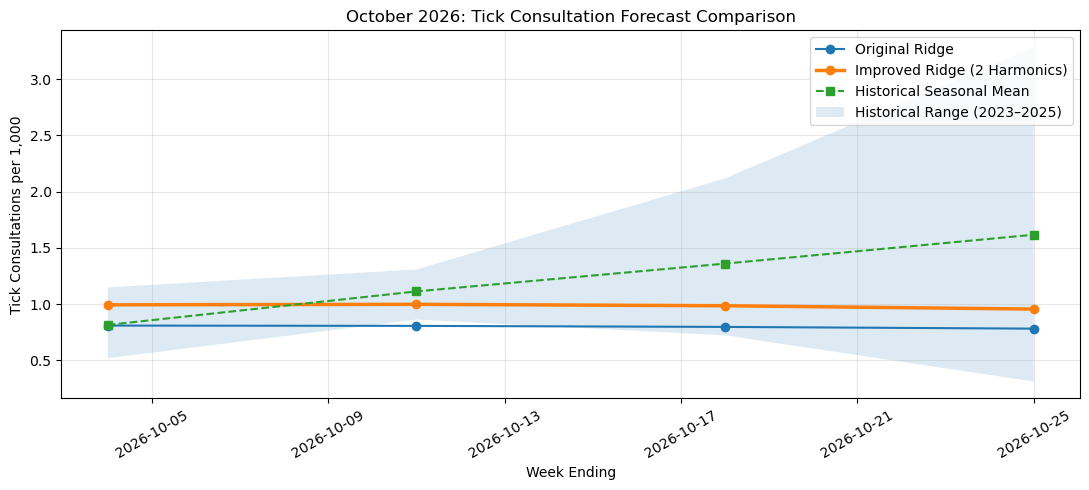

In [101]:
# STEP 88: Compare October 2026 forecasts

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.plot(
    comparison_oct["Week_End"],
    comparison_oct["Ridge_Forecast_per_1000"],
    marker="o",
    label="Original Ridge"
)

plt.plot(
    comparison_oct["Week_End"],
    comparison_oct["Ridge_2H_Forecast"],
    marker="o",
    linewidth=2.5,
    label="Improved Ridge (2 Harmonics)"
)

plt.plot(
    comparison_oct["Week_End"],
    comparison_oct["Seasonal_Mean"],
    marker="s",
    linestyle="--",
    label="Historical Seasonal Mean"
)

plt.fill_between(
    comparison_oct["Week_End"],
    comparison_oct["Historical_Min"],
    comparison_oct["Historical_Max"],
    alpha=0.15,
    label="Historical Range (2023–2025)"
)

plt.title("October 2026: Tick Consultation Forecast Comparison")
plt.xlabel("Week Ending")
plt.ylabel("Tick Consultations per 1,000")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [102]:
# STEP 89: Prepare data for Binomial GLM
'''Unlike Ridge, which predicts the tick rate directly, a Binomial GLM models tick consultations out of total consultations.
We'll start with a regional model using seasonality only, then test whether adding other predictors improves it.'''

import pandas as pd
import numpy as np
import statsmodels.api as sm

glm_df = seq_weekly.copy().sort_values("Week_End")

# Annual seasonality
week_num = glm_df["Week_End"].dt.isocalendar().week.astype(int)

glm_df["Season_Sin"] = np.sin(2 * np.pi * week_num / 52.18)
glm_df["Season_Cos"] = np.cos(2 * np.pi * week_num / 52.18)

# Second seasonal harmonic
glm_df["Season_Sin2"] = np.sin(4 * np.pi * week_num / 52.18)
glm_df["Season_Cos2"] = np.cos(4 * np.pi * week_num / 52.18)

# Tick consultations must not exceed total consultations
glm_df = glm_df[
    (glm_df["Total_Consultations"] > 0) &
    (glm_df["Tick_Consultations"] >= 0) &
    (glm_df["Tick_Consultations"] <= glm_df["Total_Consultations"])
].copy()

print("Weeks available:", len(glm_df))
print("Date range:", glm_df["Week_End"].min(), "to", glm_df["Week_End"].max())

display(glm_df[
    ["Week_End", "Total_Consultations",
     "Tick_Consultations", "Tick_per_1000"]
].tail())

Weeks available: 252
Date range: 2021-10-03 00:00:00 to 2026-07-26 00:00:00


,Week_End,Total_Consultations,Tick_Consultations,Tick_per_1000
247,2026-06-28,3031,0,0.000000
248,2026-07-05,2839,2,0.704473
249,2026-07-12,2749,2,0.727537
250,2026-07-19,2749,3,1.091306
251,2026-07-26,2713,1,0.368596


In [103]:
'''We'll train on data before 2025 and evaluate on January 2025 – July 2026, consistent with our earlier Ridge comparison.'''

# STEP 90: Train and evaluate seasonal Binomial GLM

from sklearn.metrics import mean_absolute_error, mean_squared_error
import statsmodels.api as sm
import numpy as np

glm_features = [
    "Season_Sin", "Season_Cos",
    "Season_Sin2", "Season_Cos2"
]

glm_train = glm_df[glm_df["Week_End"] < "2025-01-01"].copy()
glm_test = glm_df[glm_df["Week_End"] >= "2025-01-01"].copy()

# Proportion of consultations related to ticks
glm_train["Tick_Proportion"] = (
    glm_train["Tick_Consultations"] /
    glm_train["Total_Consultations"]
)

# Binomial GLM with consultation counts as weights
glm_model = sm.GLM(
    glm_train["Tick_Proportion"],
    sm.add_constant(glm_train[glm_features], has_constant="add"),
    family=sm.families.Binomial(),
    var_weights=glm_train["Total_Consultations"]
).fit()

# Predict tick rate per 1,000 consultations
glm_test["GLM_Predicted_per_1000"] = (
    glm_model.predict(
        sm.add_constant(glm_test[glm_features], has_constant="add")
    ) * 1000
)

glm_mae = mean_absolute_error(
    glm_test["Tick_per_1000"],
    glm_test["GLM_Predicted_per_1000"]
)

glm_rmse = np.sqrt(mean_squared_error(
    glm_test["Tick_per_1000"],
    glm_test["GLM_Predicted_per_1000"]
))

print("TRAINING WEEKS:", len(glm_train))
print("TESTING WEEKS:", len(glm_test))
print("GLM MAE:", round(glm_mae, 4))
print("GLM RMSE:", round(glm_rmse, 4))

print("\nMODEL COEFFICIENTS")
display(glm_model.summary().tables[1])

TRAINING WEEKS: 170
TESTING WEEKS: 82
GLM MAE: 0.2575
GLM RMSE: 0.4054

MODEL COEFFICIENTS


,coef,std err,z,P>|z|,[0.025,0.975]
const,-8.5301,0.097,-87.550,0.000,-8.721,-8.339
Season_Sin,-1.5119,0.148,-10.230,0.000,-1.802,-1.222
Season_Cos,0.0787,0.120,0.658,0.510,-0.156,0.313
Season_Sin2,-0.1934,0.103,-1.874,0.061,-0.396,0.009
Season_Cos2,-0.0194,0.103,-0.187,0.851,-0.222,0.183


In [104]:
# STEP 91: Backtest Binomial GLM for Aug-Oct, 2023-2025

from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np
import statsmodels.api as sm

glm_backtest_results = []
glm_backtest_predictions = []

for year in [2023, 2024, 2025]:

    cutoff = pd.Timestamp(f"{year}-07-31")

    train = glm_df[glm_df["Week_End"] <= cutoff].copy()

    test = glm_df[
        (glm_df["Week_End"] > cutoff) &
        (glm_df["Week_End"] <= pd.Timestamp(f"{year}-10-31"))
    ].copy()

    # Fit only using data available before the forecast period
    train["Tick_Proportion"] = (
        train["Tick_Consultations"] /
        train["Total_Consultations"]
    )

    model = sm.GLM(
        train["Tick_Proportion"],
        sm.add_constant(train[glm_features], has_constant="add"),
        family=sm.families.Binomial(),
        var_weights=train["Total_Consultations"]
    ).fit()

    # Predict rates using calendar seasonality
    test["GLM_Predicted"] = (
        model.predict(
            sm.add_constant(test[glm_features], has_constant="add")
        ) * 1000
    )

    glm_backtest_results.append({
        "Year": year,
        "Model": "Seasonal Binomial GLM",
        "Weeks": len(test),
        "MAE": mean_absolute_error(
            test["Tick_per_1000"], test["GLM_Predicted"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            test["Tick_per_1000"], test["GLM_Predicted"]
        ))
    })

    glm_backtest_predictions.append(
        test[["Week_End", "Tick_per_1000", "GLM_Predicted"]]
    )

glm_backtest_results = pd.DataFrame(glm_backtest_results)

print("GLM BACKTEST RESULTS")
display(glm_backtest_results.round(4))

print("\nAVERAGE PERFORMANCE")
display(
    glm_backtest_results[["MAE", "RMSE"]]
    .mean()
    .round(4)
)

GLM BACKTEST RESULTS


,Year,Model,Weeks,MAE,RMSE
0,2023,Seasonal Binomial GLM,13,0.3549,0.4233
1,2024,Seasonal Binomial GLM,13,0.4441,0.7331
2,2025,Seasonal Binomial GLM,13,0.4610,0.5378



AVERAGE PERFORMANCE


MAE     0.4200
RMSE    0.5647
dtype: float64

In [105]:
# STEP 92: October 2026 forecast using Binomial GLM

# Fit GLM using all available data through July 2026
glm_full = glm_df.copy()

glm_full["Tick_Proportion"] = (
    glm_full["Tick_Consultations"] /
    glm_full["Total_Consultations"]
)

glm_final = sm.GLM(
    glm_full["Tick_Proportion"],
    sm.add_constant(glm_full[glm_features], has_constant="add"),
    family=sm.families.Binomial(),
    var_weights=glm_full["Total_Consultations"]
).fit()

# Create October 2026 forecast dates
oct_weeks = pd.date_range(
    "2026-10-01", "2026-10-31", freq="W-SUN"
)

glm_future = pd.DataFrame({"Week_End": oct_weeks})

week_num = glm_future["Week_End"].dt.isocalendar().week.astype(int)

glm_future["Season_Sin"] = np.sin(2 * np.pi * week_num / 52.18)
glm_future["Season_Cos"] = np.cos(2 * np.pi * week_num / 52.18)
glm_future["Season_Sin2"] = np.sin(4 * np.pi * week_num / 52.18)
glm_future["Season_Cos2"] = np.cos(4 * np.pi * week_num / 52.18)

# Predict consultations per 1,000
glm_future["GLM_Forecast_per_1000"] = (
    glm_final.predict(
        sm.add_constant(glm_future[glm_features], has_constant="add")
    ) * 1000
)

# Compare all forecasts
final_comparison = comparison_oct.merge(
    glm_future[["Week_End", "GLM_Forecast_per_1000"]],
    on="Week_End"
)

display(final_comparison.round(3))

final_comparison.to_csv(
    "our_october_2026_all_models.csv",
    index=False
)

,Week_End,Ridge_Forecast_per_1000,ISO_Week,Seasonal_Mean,Seasonal_Median,Historical_Min,Historical_Max,Ridge_2H_Forecast,GLM_Forecast_per_1000
0,2026-10-04,0.809,40,0.814,0.776,0.518,1.148,0.993,1.010
1,2026-10-11,0.806,41,1.112,1.168,0.862,1.308,0.997,1.030
2,2026-10-18,0.797,42,1.360,1.240,0.722,2.118,0.985,1.025
3,2026-10-25,0.781,43,1.616,1.253,0.311,3.285,0.955,0.992


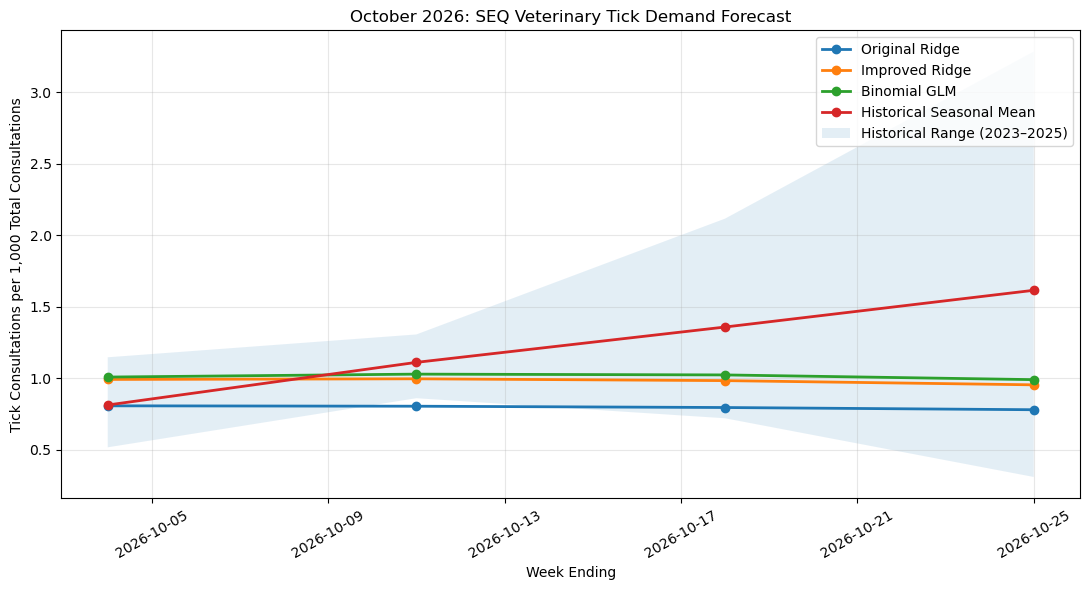

In [106]:
# STEP 93: Final October 2026 forecast comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

for column, label in [
    ("Ridge_Forecast_per_1000", "Original Ridge"),
    ("Ridge_2H_Forecast", "Improved Ridge"),
    ("GLM_Forecast_per_1000", "Binomial GLM"),
    ("Seasonal_Mean", "Historical Seasonal Mean")
]:
    plt.plot(
        final_comparison["Week_End"],
        final_comparison[column],
        marker="o",
        linewidth=2,
        label=label
    )

plt.fill_between(
    final_comparison["Week_End"],
    final_comparison["Historical_Min"],
    final_comparison["Historical_Max"],
    alpha=0.12,
    label="Historical Range (2023–2025)"
)

plt.title("October 2026: SEQ Veterinary Tick Demand Forecast")
plt.xlabel("Week Ending")
plt.ylabel("Tick Consultations per 1,000 Total Consultations")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "our_october_2026_final_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()